# 05. AlphaProg-AGMT: graph history, censored effort and adaptive fusion


In [1]:
from pathlib import Path
import json
import hashlib


def verify_frozen_training_source(root: Path) -> None:
    """Allow exact-source reproduction without pretending a viewed test is new."""
    boundary = root / "Protocol/test_evaluation_boundary.json"
    if not boundary.exists():
        return
    frozen_sources = json.loads(
        (root / "Protocol/frozen_training_sources.json").read_text()
    )
    for filename, expected in frozen_sources["notebooks"].items():
        notebook = json.loads((root / "Notebooks" / filename).read_text())
        source = "\n\n".join(
            "".join(cell["source"])
            for cell in notebook["cells"]
            if cell["cell_type"] == "code"
        )
        observed = hashlib.sha256(source.encode()).hexdigest()
        assert (
            observed == expected
        ), "Training source changed after the test was opened."


import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
assert ROOT.name == "ALPHA"
SEED = 20260923
rng = np.random.default_rng(SEED)
font_names = {font.name for font in font_manager.fontManager.ttflist}
assert "Times New Roman" in font_names
FONT = "Times New Roman"
FONT_SIZE, TITLE_SIZE, FIGURE_DPI = 18, 20, 350
mpl.rcParams.update(
    {
        "font.family": FONT,
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "mathtext.fontset": "stix",
    }
)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


def table(frame: pd.DataFrame, caption: str, name: str) -> None:
    """Display a complete DataFrame using Jupyter's default table styling."""
    frame.to_csv(ROOT / "Tables" / f"{name}.csv", index=False)
    with pd.option_context(
        "display.max_rows",
        None,
        "display.max_columns",
        None,
        "display.max_colwidth",
        None,
        "display.width",
        None,
    ):
        display(Markdown(caption))
        display(frame.reset_index(drop=True).round(5))


def save_figure(fig: mpl.figure.Figure, name: str) -> None:
    """Save at 350 dpi after checking the font contract on visible text."""
    from matplotlib.text import Text

    fig.canvas.draw()
    for text in fig.findobj(match=Text):
        if text.get_visible() and text.get_text():
            assert 18 <= text.get_fontsize() <= 20
            assert text.get_fontfamily() == ["Times New Roman"]
    fig.savefig(ROOT / "Figures" / f"{name}.png", dpi=FIGURE_DPI)
    fig.savefig(ROOT / "Figures" / f"{name}.pdf", dpi=FIGURE_DPI)


import time
import random
import gc
from dataclasses import replace
from typing import Any
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)
from lightgbm import LGBMClassifier
import torch
from torch import nn
from torch.nn import functional as F
from scipy.optimize import minimize
from scipy.special import expit

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(2)
SEEDS = [17, 42, 2026]
protocol = json.loads(
    (ROOT / "Protocol/robomission_protocol.json").read_text()
)
verify_frozen_training_source(ROOT)
# The candidate screen was registered before execution; selection uses validation only.
development_protocol = json.loads(
    (ROOT / "Protocol/model_development_protocol.json").read_text()
)
assert development_protocol["integrity"]["selection_split"] == "Validation"
base_decision = json.loads(
    (ROOT / "Protocol/model_base_selection.json").read_text()
)
BASE_NAME = base_decision["base"]
contract = json.loads(
    (ROOT / "Protocol/robo_feature_contract.json").read_text()
)
feature_names = contract["features"]
numeric_names = [
    name for name in feature_names if name not in contract["categorical"]
]
train_data = pd.read_pickle(
    ROOT / "Data/Processed/robo_features_train.pkl"
).reset_index(drop=True)
validation_data = pd.read_pickle(
    ROOT / "Data/Processed/robo_features_validation.pkl"
).reset_index(drop=True)
assert set(train_data.student).isdisjoint(validation_data.student)
assert contract["feature_revision"] == "event_prefix_v2"
assert (
    train_data.attrs["feature_revision"]
    == validation_data.attrs["feature_revision"]
    == "event_prefix_v2"
)
modern_execution = json.loads(
    (ROOT / "Protocol/modern_execution.json").read_text()
)
assert (
    modern_execution["completed"]
    and modern_execution["feature_revision"] == contract["feature_revision"]
)
episode_data = pd.read_pickle(
    ROOT / "Data/Processed/robo_episode_features.pkl"
)
graph_archive = json.loads(
    (ROOT / "Data/Processed/program_graphs.json").read_text()
)
problem_metadata = pd.read_pickle(
    ROOT / "Data/Processed/robo_problem_features.pkl"
)
problem_to_index = {
    int(problem): index + 1
    for index, problem in enumerate(sorted(problem_metadata.index))
}
N_TASKS = len(problem_to_index)
GRAPH_MODEL_DIR = ROOT / "Results/proposed"
GRAPH_MODEL_DIR.mkdir(exist_ok=True)
graph_curves, graph_efficiency = [], []
component_results, hazard_results, gate_results = {}, {}, {}

## Coverage of the structural representation

What share of code can be represented structurally, and what share requires a fallback character sequence? The table describes the prefixes actually available in the input sequences. Reuse of a single past state in several queries is counted as several context positions; the number of unique programs is shown separately. The limit of 64 nodes is fixed before quality is evaluated.

In [2]:
coverage = []
for split, frame in [("Train", train_data), ("Validation", validation_data)]:
    source = pd.read_pickle(
        ROOT / f"Data/Processed/robo_sequences_{split.lower()}.pkl"
    )
    columns = {name: index for index, name in enumerate(source["columns"])}
    observed_rows = np.asarray(
        [row for history in source["sequences"] for row in history],
        dtype=float,
    )
    used_ids = observed_rows[:, columns["graph_id"]].astype(int)
    counts = np.asarray(
        [len(graph_archive["graphs"][index]["labels"]) for index in used_ids]
    )
    coverage.append(
        {
            "Split": split,
            "n": len(observed_rows),
            "Programs": len(np.unique(used_ids)),
            "Invalid fraction": observed_rows[
                :, columns["code_invalid"]
            ].mean(),
            "Over 64 nodes": (counts > 64).mean(),
            "Median nodes": np.median(counts),
        }
    )
table(
    pd.DataFrame(coverage),
    "Table 1. Coverage of program structures",
    "05_graph_coverage",
)

Table 1. Coverage of program structures

,Split,n,Programs,Invalid fraction,Over 64 nodes,Median nodes
0,Train,1137570,4960,0.00142,0.0,5.0
1,Validation,237999,1640,0.00102,0.0,5.0


## Architecture and training paths

The diagram shows the flow of available inputs and predictions. Training uses target labels only in the loss functions. The fusion weights are estimated only after the OOF predictions of the components have been obtained. The current program, its final number of runs and its success are never input features.

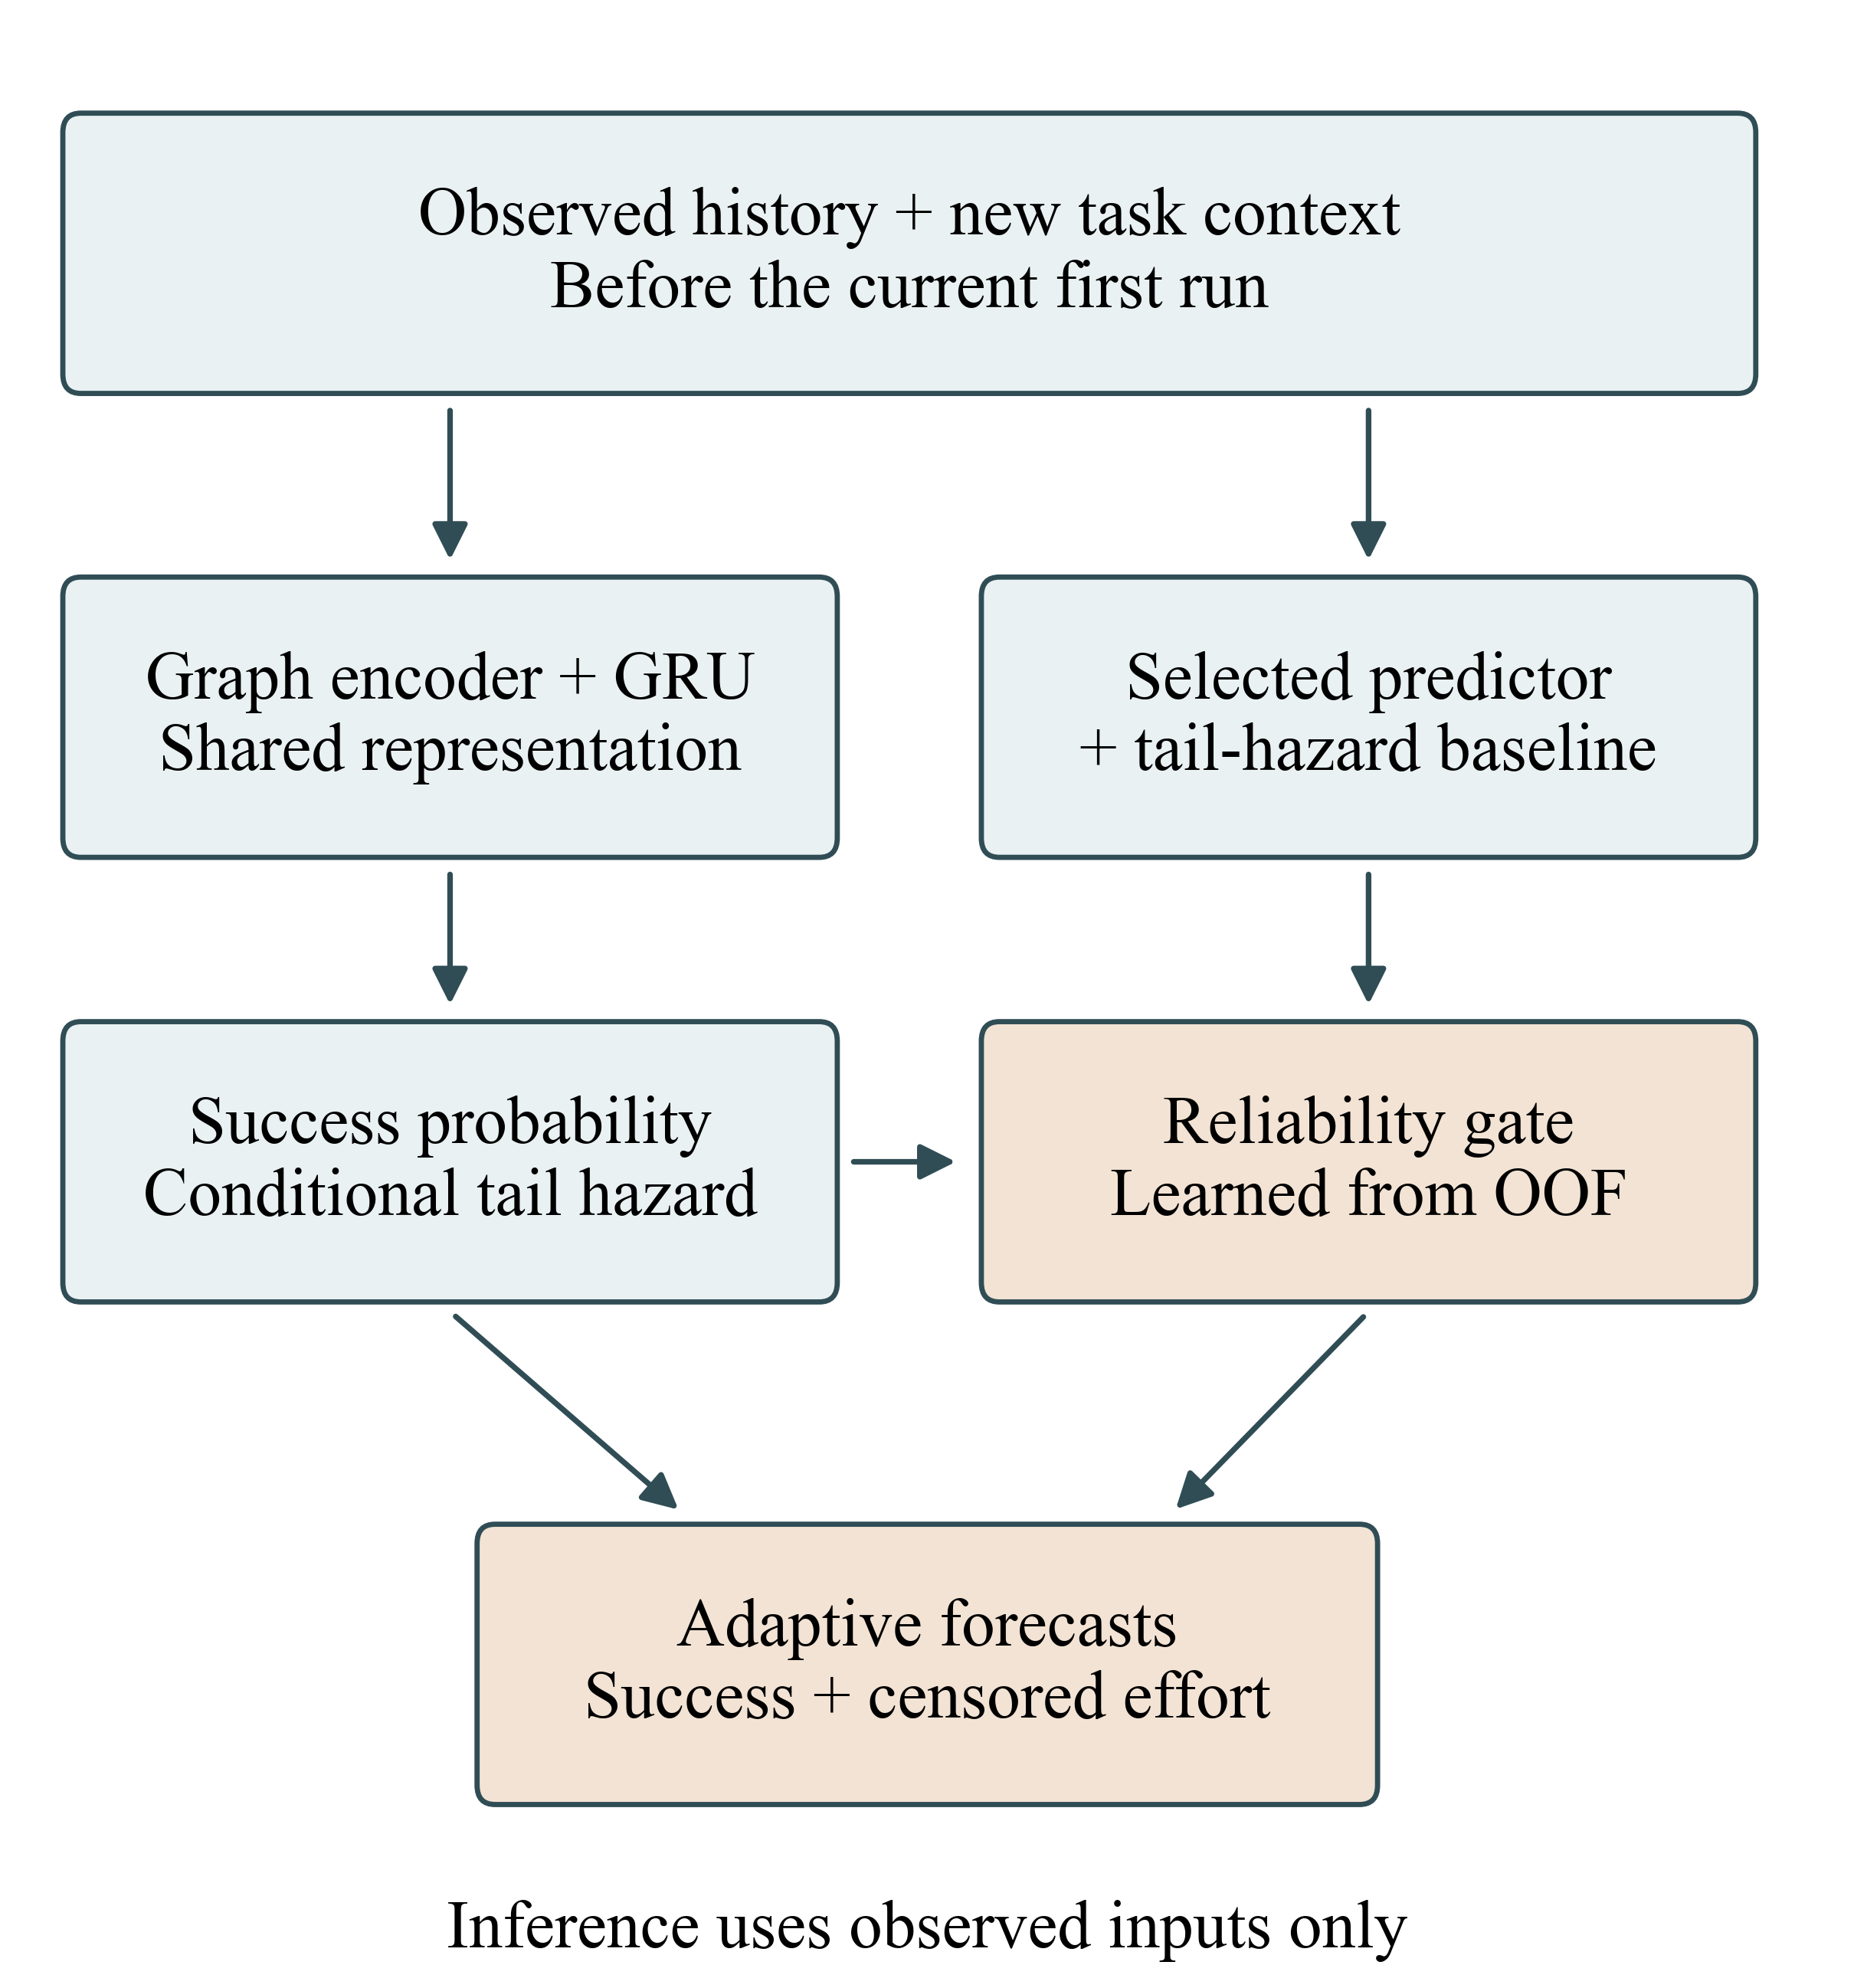

In [3]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(6.8, 7.3), layout="constrained")
ax.set(xlim=(0, 10), ylim=(0, 10))
ax.axis("off")
boxes = {
    "inputs": (
        0.3,
        8.2,
        9.2,
        1.25,
        "Observed history + new task context\nBefore the current first run",
    ),
    "graph": (
        0.3,
        5.8,
        4.1,
        1.25,
        "Graph encoder + GRU\nShared representation",
    ),
    "base": (
        5.4,
        5.8,
        4.1,
        1.25,
        "Selected predictor\n+ tail-hazard baseline",
    ),
    "expert": (
        0.3,
        3.5,
        4.1,
        1.25,
        "Success probability\nConditional tail hazard",
    ),
    "gate": (5.4, 3.5, 4.1, 1.25, "Reliability gate\nLearned from OOF"),
    "result": (
        2.6,
        0.9,
        4.8,
        1.25,
        "Adaptive forecasts\nSuccess + censored effort",
    ),
}
for key, (x, y, width, height, label) in boxes.items():
    color = "#E9F1F2" if key not in ["gate", "result"] else "#F2E3D4"
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            width,
            height,
            boxstyle="round,pad=0.10",
            facecolor=color,
            edgecolor="#304D55",
            linewidth=1.4,
        )
    )
    ax.text(
        x + width / 2,
        y + height / 2,
        label,
        ha="center",
        va="center",
        fontsize=18,
    )
for start, end in [
    ((2.35, 8.05), (2.35, 7.2)),
    ((7.45, 8.05), (7.45, 7.2)),
    ((2.35, 5.65), (2.35, 4.9)),
    ((7.45, 5.65), (7.45, 4.9)),
    ((4.55, 4.125), (5.2, 4.125)),
    ((7.45, 3.35), (6.35, 2.3)),
    ((2.35, 3.35), (3.65, 2.3)),
]:
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle="-|>",
            mutation_scale=20,
            color="#304D55",
            linewidth=1.5,
        )
    )
ax.text(
    5,
    0.15,
    "Inference uses observed inputs only",
    ha="center",
    va="center",
    fontsize=18,
)
save_figure(fig, "05_architecture")
plt.show()

## Components and loss functions




In [4]:
import math
from dataclasses import dataclass


@dataclass(frozen=True)
class GraphConfig:
    """Explicit capacity and ablation controls; the defaults are the regularised screen candidate."""

    width: int = 32
    graph_steps: int = 2
    use_code: bool = True
    use_edges: bool = True
    use_recurrence: bool = True
    use_solution: bool = False
    use_task_attention: bool = False
    attention_heads: int = 4
    auxiliary_weight: float = 0.1
    weight_decay: float = 1e-4
    dropout: float = 0.1
    learning_rate: float = 0.001
    max_nodes: int = 64
    use_interaction: bool = False
    use_task_readout: bool = False


# Observed outcome state of a prior attempt: first run (not observed, incorrect,
# correct) crossed with the solved flag; index 0 of the embedding is padding.
N_OUTCOME_STATES = 6
N_INTERACTIONS = 1 + N_TASKS * N_OUTCOME_STATES


class ProgramGraphEncoder(nn.Module):
    """Encode command content, nesting and ordered sibling relations."""

    def __init__(
        self,
        vocabulary_size: int,
        width: int,
        steps: int,
        use_edges: bool,
        graph_tensors: dict[str, torch.Tensor],
        solution_tensors: dict[str, torch.Tensor] | None = None,
    ):
        super().__init__()
        self.use_edges = use_edges
        self.embedding = nn.Embedding(vocabulary_size, width, padding_idx=0)
        self.self_maps = nn.ModuleList(
            nn.Linear(width, width) for _ in range(steps)
        )
        self.parent_maps = nn.ModuleList(
            nn.Linear(width, width, bias=False) for _ in range(steps)
        )
        self.previous_maps = nn.ModuleList(
            nn.Linear(width, width, bias=False) for _ in range(steps)
        )
        self.norms = nn.ModuleList(nn.LayerNorm(width) for _ in range(steps))
        for name, values in graph_tensors.items():
            # Syntax is input data, not learned state or a program-ID embedding.
            self.register_buffer(name, values, persistent=False)
        for name, values in (solution_tensors or {}).items():
            # Reference solutions are static task descriptions, indexed by task.
            self.register_buffer(f"solution_{name}", values, persistent=False)

    def encode(
        self,
        token: torch.Tensor,
        parent: torch.Tensor,
        previous: torch.Tensor,
        node_mask: torch.Tensor,
    ) -> torch.Tensor:
        """Pool node states of a batch of program graphs."""
        mask = node_mask.unsqueeze(-1)
        hidden = self.embedding(token) * mask
        for own_map, parent_map, previous_map, norm in zip(
            self.self_maps, self.parent_maps, self.previous_maps, self.norms
        ):
            messages = own_map(hidden)
            if self.use_edges:
                parent_hidden = hidden.gather(
                    1, parent.clamp(min=0).unsqueeze(-1).expand_as(hidden)
                )
                previous_hidden = hidden.gather(
                    1, previous.clamp(min=0).unsqueeze(-1).expand_as(hidden)
                )
                messages = messages + parent_map(parent_hidden) * (
                    parent >= 0
                ).unsqueeze(-1)
                messages = messages + previous_map(previous_hidden) * (
                    previous >= 0
                ).unsqueeze(-1)
            else:
                # Keep every parameter active in the topology-free capacity control.
                messages = messages + parent_map(hidden) + previous_map(hidden)
            hidden = norm(hidden + F.gelu(messages)) * mask
        return hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)

    def forward(self, graph_ids: torch.Tensor) -> torch.Tensor:
        unique_ids, inverse = torch.unique(graph_ids, return_inverse=True)
        pooled = self.encode(
            self.token[unique_ids],
            self.parent[unique_ids],
            self.previous[unique_ids],
            self.node_mask[unique_ids],
        )
        return pooled[inverse].reshape(*graph_ids.shape, pooled.shape[-1])

    def solutions(self, task: torch.Tensor) -> torch.Tensor:
        """Encode the reference solution of each target task with shared weights."""
        unique_ids, inverse = torch.unique(task, return_inverse=True)
        pooled = self.encode(
            self.solution_token[unique_ids],
            self.solution_parent[unique_ids],
            self.solution_previous[unique_ids],
            self.solution_node_mask[unique_ids],
        )
        return pooled[inverse]


class TrajectoryExpert(nn.Module):
    """Share a causal graph and process-history representation across two tasks."""

    def __init__(
        self,
        vocabulary_size: int,
        graph_tensors: dict[str, torch.Tensor],
        n_process: int,
        n_context: int,
        config: GraphConfig,
        solution_tensors: dict[str, torch.Tensor] | None = None,
    ):
        super().__init__()
        assert config.use_code or not config.use_solution
        assert not config.use_solution or solution_tensors
        self.config = config
        self.code = (
            ProgramGraphEncoder(
                vocabulary_size,
                config.width,
                config.graph_steps,
                config.use_edges,
                graph_tensors,
                solution_tensors if config.use_solution else None,
            )
            if config.use_code
            else None
        )
        # Identity of each prior task together with its observed outcome state.
        self.interaction = (
            nn.Embedding(N_INTERACTIONS, config.width // 2, padding_idx=0)
            if config.use_interaction
            else None
        )
        self.event_projection = nn.Sequential(
            nn.Linear(
                (config.width if config.use_code else 0)
                + n_process
                + (config.width // 2 if config.use_interaction else 0),
                config.width,
            ),
            nn.GELU(),
            nn.Dropout(config.dropout),
        )
        self.recurrent = (
            nn.GRU(config.width, config.width, batch_first=True)
            if config.use_recurrence
            else None
        )
        self.context = nn.Sequential(
            nn.Linear(n_context, config.width), nn.GELU()
        )
        self.solution = (
            nn.Sequential(nn.Linear(config.width, config.width), nn.GELU())
            if config.use_solution
            else None
        )
        n_target = 2 if config.use_solution else 1
        if config.use_task_attention:
            assert config.width % config.attention_heads == 0
            self.query = nn.Linear(n_target * config.width, config.width)
            self.key = nn.Linear(config.width, config.width)
            self.value = nn.Linear(config.width, config.width)
            # A learned empty slot lets the target task ignore every prior attempt.
            self.empty_slot = nn.Parameter(torch.zeros(1, 1, config.width))
        n_shared = 1 + n_target + int(config.use_task_attention)
        self.shared = nn.Sequential(
            nn.Linear(n_shared * config.width, config.width),
            nn.GELU(),
            nn.Dropout(config.dropout),
        )
        self.success = nn.Linear(config.width, 1)
        self.tail_hazard = nn.Linear(config.width, 1)
        if config.use_task_readout:
            # Task-specific read-out; zero initialisation leaves unknown tasks neutral.
            self.success_readout = nn.Embedding(N_TASKS + 1, config.width)
            self.hazard_readout = nn.Embedding(N_TASKS + 1, config.width)
            nn.init.zeros_(self.success_readout.weight)
            nn.init.zeros_(self.hazard_readout.weight)
        if config.auxiliary_weight == 0:
            self.tail_hazard.requires_grad_(False)
            if config.use_task_readout:
                self.hazard_readout.requires_grad_(False)

    def attend(
        self, target: torch.Tensor, states: torch.Tensor, length: torch.Tensor
    ) -> torch.Tensor:
        """Read the observed history with a query formed by the target task."""
        batch, steps, width = states.shape
        heads = self.config.attention_heads
        size = width // heads
        memory = torch.cat(
            [self.empty_slot.expand(batch, 1, width), states], dim=1
        )
        positions = torch.arange(steps, device=states.device).unsqueeze(0)
        valid = torch.cat(
            [
                torch.ones(batch, 1, dtype=torch.bool, device=states.device),
                positions < length.unsqueeze(1),
            ],
            dim=1,
        )
        query = self.query(target).reshape(batch, heads, 1, size)
        key = self.key(memory).reshape(batch, steps + 1, heads, size)
        value = self.value(memory).reshape(batch, steps + 1, heads, size)
        scores = (query @ key.transpose(1, 2).transpose(-1, -2)) / math.sqrt(size)
        scores = scores.masked_fill(~valid[:, None, None, :], float("-inf"))
        weights = scores.softmax(dim=-1)
        return (weights @ value.transpose(1, 2)).reshape(batch, width)

    def forward(
        self, batch: dict[str, torch.Tensor]
    ) -> tuple[torch.Tensor, torch.Tensor]:
        content = (
            torch.cat([self.code(batch["graph_id"]), batch["process"]], dim=-1)
            if self.code is not None
            else batch["process"]
        )
        if self.interaction is not None:
            content = torch.cat(
                [content, self.interaction(batch["interaction"])], dim=-1
            )
        episodes = self.event_projection(content)
        length = batch["length"]
        if self.config.use_recurrence:
            states, _ = self.recurrent(episodes)
            rows = torch.arange(len(length), device=states.device)
            history = states[rows, (length - 1).clamp(min=0)]
        else:
            states = episodes
            steps = torch.arange(
                episodes.shape[1], device=episodes.device
            ).unsqueeze(0)
            valid = (steps < length.unsqueeze(1)).unsqueeze(-1)
            history = (episodes * valid).sum(dim=1) / length.clamp(
                min=1
            ).unsqueeze(1)
        history = history * (length > 0).unsqueeze(1)
        target = [self.context(batch["context"])]
        if self.solution is not None:
            target.append(self.solution(self.code.solutions(batch["solution"])))
        parts = [history, *target]
        if self.config.use_task_attention:
            parts.append(self.attend(torch.cat(target, dim=1), states, length))
        hidden = self.shared(torch.cat(parts, dim=1))
        success = self.success(hidden).squeeze(-1)
        hazard = self.tail_hazard(hidden).squeeze(-1)
        if self.config.use_task_readout:
            success = success + (
                self.success_readout(batch["task"]) * hidden
            ).sum(dim=-1)
            hazard = hazard + (
                self.hazard_readout(batch["task"]) * hidden
            ).sum(dim=-1)
        return success, hazard


def trajectory_loss(
    success_logit: torch.Tensor,
    hazard_logit: torch.Tensor,
    batch: dict[str, torch.Tensor],
    auxiliary_weight: float,
) -> torch.Tensor:
    """Combine first-run BCE with a right-censored geometric tail likelihood."""
    primary = F.binary_cross_entropy_with_logits(success_logit, batch["y"])
    failed_first = 1 - batch["y"]
    remaining_runs = (batch["effort_runs"] - 1).clamp(min=0)
    event = batch["effort_observed"] * failed_first
    failures = remaining_runs * failed_first - event
    assert bool((failures >= 0).all().item())
    likelihood = event * F.softplus(-hazard_logit) + failures * F.softplus(
        hazard_logit
    )
    # Exposure normalization keeps long censored records from setting loss scale.
    exposure = (event + failures).sum().clamp(min=1)
    return primary + auxiliary_weight * likelihood.sum() / exposure

In [5]:
GRAPH_HISTORY = 32

OBSERVED_PROCESS_COLUMNS = [
    "solved",
    "first_correct",
    "first_observed",
    "log_time",
    "log_n_edits",
    "log_n_executions",
    "local_code_mean",
    "local_code_std",
    "code_f",
    "code_l",
    "code_r",
    "code_s",
    "code_R",
    "code_W",
    "code_I",
    "code_ELSE",
    "code_UNKNOWN",
    "code_nodes",
    "code_depth",
    "code_length",
    "code_depth_sum",
    "code_invalid",
]


HISTORY_TASK_FEATURES = {
    "task_level": "q_level",
    "task_diamonds": "q_diamonds",
    "task_repeat": "q_repeat",
    "task_while": "q_while",
    "task_if": "q_if",
    "task_if_else": "q_if-else",
    "task_position": "q_position",
    "task_shoot": "q_shoot",
}

PROCESS_COLUMNS = OBSERVED_PROCESS_COLUMNS + list(HISTORY_TASK_FEATURES)


# Verbatim copy of the notebook 02 parser; task solutions use the same language.
import re
from collections import Counter

NODE_TYPES = ["ROOT", "f", "l", "r", "s", "R", "W", "I", "ELSE", "UNKNOWN"]
TYPE_ID = {s: i for i, s in enumerate(NODE_TYPES)}


def parse_minicode(program: str) -> dict:
    """Parse command/control nesting and sibling order; preserve invalid code."""
    labels, parents, previous = ["ROOT"], [-1], [-1]
    position = 0

    def block(parent: int, expect_close: bool = False) -> None:
        nonlocal position
        prior = -1
        while position < len(program) and program[position] != "}":
            char = program[position]
            position += 1
            if char in "flrs":
                label = char
            elif char in "RWI/":
                start = position
                while position < len(program) and program[position] != "{":
                    if program[position] in "}":
                        raise ValueError("missing opening brace")
                    position += 1
                if position >= len(program):
                    raise ValueError("incomplete control")
                arg = program[start:position]
                if char == "R" and not re.fullmatch(r"\d+", arg):
                    raise ValueError("invalid repeat")
                if char in "WI" and not re.fullmatch(
                    r"!?[bgkdy]|x(?:!=|<=|>=|[<>=])\d+", arg
                ):
                    raise ValueError("invalid condition")
                if char == "/" and arg:
                    raise ValueError("invalid else")
                label = ("ELSE" if char == "/" else char) + (
                    ":" + arg if arg else ""
                )
            else:
                raise ValueError("unknown token")
            index = len(labels)
            labels.append(label)
            parents.append(parent)
            previous.append(prior)
            prior = index
            if char in "RWI/":
                position += 1
                block(index, expect_close=True)
        if expect_close:
            if position >= len(program) or program[position] != "}":
                raise ValueError("missing closing brace")
            position += 1

    try:
        block(0)
        if position != len(program):
            raise ValueError("unmatched brace")
        valid = True
    except ValueError:
        labels = ["ROOT"] + [("UNKNOWN:" + c) for c in program]
        parents = [-1] + [0] * len(program)
        previous = (
            [-1] + [-1] + list(range(1, len(program))) if program else [-1]
        )
        valid = False
    depths = [0]
    for parent in parents[1:]:
        depths.append(depths[parent] + 1)
    kinds = [label.split(":")[0] for label in labels]
    counts = Counter(kinds)
    features = {f"code_{kind}": counts[kind] for kind in NODE_TYPES[1:]}
    features.update(
        code_nodes=len(labels) - 1,
        code_depth=max(depths),
        code_length=len(program),
        code_depth_sum=sum(depths),
        code_invalid=int(not valid),
    )
    return {
        "types": [TYPE_ID[kind] for kind in kinds],
        "labels": labels,
        "parents": parents,
        "previous": previous,
        "features": features,
        "valid": valid,
    }


assert all(
    parse_minicode(program) == graph
    for program, graph in zip(graph_archive["programs"], graph_archive["graphs"])
), "The copied parser differs from the parser that built the program archive."
problem_table = pd.read_pickle(ROOT / "Data/Processed/robo_problems.pkl")


def normalise_solution(program: str) -> str:
    """Write red conditions as 'd', the code used in learner programs (dataset README)."""
    return re.sub(r"([WI]!?)r\{", r"\1d{", program)


solution_by_task = {
    int(task): normalise_solution(program)
    for task, program in zip(problem_table.id, problem_table.solution)
}
assert set(solution_by_task) == set(problem_to_index)
task_order = sorted(problem_to_index, key=problem_to_index.get)
# Index 0 is the unknown task and receives an empty solution graph.
SOLUTION_CATALOG = {
    "problems": [0] + task_order,
    "programs": [""] + [solution_by_task[task] for task in task_order],
    "graphs": [{"labels": [], "parents": [], "previous": []}]
    + [parse_minicode(solution_by_task[task]) for task in task_order],
}
assert all(graph["valid"] for graph in SOLUTION_CATALOG["graphs"][1:])
# The solution lookup is task metadata and stays available when task identity is masked.
SOLUTION_INDEX = {
    task: index for index, task in enumerate(SOLUTION_CATALOG["problems"]) if index
}


def graph_history_arrays(
    frame: pd.DataFrame,
    sequence_source: dict,
    task_metadata: pd.DataFrame,
) -> dict[str, np.ndarray]:
    """Encode observed past prefixes together with their known task descriptions."""

    assert sequence_source["feature_revision"] == "event_prefix_v2"

    assert np.array_equal(
        frame.id.to_numpy(),
        np.asarray(sequence_source["ids"]),
    )

    column_index = {
        name: index
        for index, name in enumerate(sequence_source["columns"])
    }

    assert task_metadata.index.is_unique

    metadata_values = task_metadata.loc[
        :,
        list(HISTORY_TASK_FEATURES.values()),
    ].to_numpy(dtype=np.float32)

    assert np.isfinite(metadata_values).all()

    task_lookup = {
        int(task): values
        for task, values in zip(
            task_metadata.index,
            metadata_values,
        )
    }

    observed_indices = [
        column_index[name]
        for name in OBSERVED_PROCESS_COLUMNS
    ]

    n_observed = len(OBSERVED_PROCESS_COLUMNS)

    graph_ids = np.zeros(
        (len(frame), GRAPH_HISTORY),
        dtype=np.int64,
    )

    process = np.full(
        (
            len(frame),
            GRAPH_HISTORY,
            len(PROCESS_COLUMNS),
        ),
        np.nan,
        dtype=np.float32,
    )

    length = np.zeros(
        len(frame),
        dtype=np.int64,
    )

    interaction = np.zeros(
        (len(frame), GRAPH_HISTORY),
        dtype=np.int64,
    )

    task_position = {
        int(task): position
        for position, task in enumerate(sorted(task_metadata.index))
    }

    def observed(history_matrix: np.ndarray, name: str) -> np.ndarray:
        return np.nan_to_num(history_matrix[:, column_index[name]]) > 0

    for row, history in enumerate(sequence_source["sequences"]):
        retained = history[-GRAPH_HISTORY:]

        length[row] = len(retained)

        # IMPORTANT:
        # retained may be a NumPy array.
        # Using `if retained:` is ambiguous for NumPy arrays.
        if len(retained) > 0:
            history_matrix = np.asarray(
                retained,
                dtype=float,
            )

            graph_ids[row, : len(retained)] = history_matrix[
                :,
                column_index["graph_id"],
            ].astype(np.int64)

            process[
                row,
                : len(retained),
                :n_observed,
            ] = history_matrix[
                :,
                observed_indices,
            ]

            prior_task_ids = history_matrix[
                :,
                column_index["problem"],
            ].astype(np.int64)

            process[
                row,
                : len(retained),
                n_observed:,
            ] = np.asarray(
                [
                    task_lookup[int(task)]
                    for task in prior_task_ids
                ],
                dtype=np.float32,
            )

            # Outcome state uses only what had been observed before the query start.
            first_run = np.where(
                observed(history_matrix, "first_observed"),
                1 + observed(history_matrix, "first_correct"),
                0,
            )
            state = 2 * first_run + observed(history_matrix, "solved")
            interaction[row, : len(retained)] = (
                1
                + np.asarray([task_position[int(task)] for task in prior_task_ids])
                * N_OUTCOME_STATES
                + state
            )

    assert interaction.max() < N_INTERACTIONS

    return {
        "graph_id": graph_ids,
        "process": process,
        "length": length,
        "interaction": interaction,
    }


def graph_vocabulary(
    fitting_graph_ids: np.ndarray,
    graph_archive: dict,
    minimum_count: int = 2,
) -> dict[str, int]:
    """Fit the node-label vocabulary only on training learners' observed code."""

    available_ids = np.unique(
        fitting_graph_ids
    ).astype(int)

    from collections import Counter

    counts = Counter(
        label
        for index in available_ids
        for label in graph_archive["graphs"][index]["labels"]
    )

    labels = sorted(
        label
        for label, count in counts.items()
        if count >= minimum_count
    )

    # 0 is padding, 1 is an unseen symbolic label.
    return {
        label: index + 2
        for index, label in enumerate(labels)
    }


def tensorize_graphs(
    graph_archive: dict,
    vocabulary: dict[str, int],
    max_nodes: int,
    device: torch.device,
) -> dict[str, torch.Tensor]:
    """Encode immutable syntax while retaining indicators for truncation elsewhere."""

    shape = (
        len(graph_archive["graphs"]),
        max_nodes,
    )

    token = np.zeros(
        shape,
        dtype=np.int64,
    )

    parent = np.full(
        shape,
        -1,
        dtype=np.int64,
    )

    previous = np.full(
        shape,
        -1,
        dtype=np.int64,
    )

    node_mask = np.zeros(
        shape,
        dtype=np.float32,
    )

    for index, graph in enumerate(
        graph_archive["graphs"]
    ):
        count = min(
            max_nodes,
            len(graph["labels"]),
        )

        token[index, :count] = [
            vocabulary.get(label, 1)
            for label in graph["labels"][:count]
        ]

        parent[index, :count] = (
            graph["parents"][:count]
        )

        previous[index, :count] = (
            graph["previous"][:count]
        )

        node_mask[index, :count] = 1

    assert np.all(parent < max_nodes)
    assert np.all(previous < max_nodes)

    return {
        name: torch.as_tensor(
            values,
            device=device,
        )
        for name, values in [
            ("token", token),
            ("parent", parent),
            ("previous", previous),
            ("node_mask", node_mask),
        ]
    }


def prepare_graph_inputs(
    fitting: np.ndarray,
    evaluation_frame: pd.DataFrame,
    evaluation_history: dict[str, np.ndarray],
) -> tuple[dict, dict, dict]:
    """Fit every numerical transform inside the training fold and align both sets."""

    fit_frame = (
        train_data
        .iloc[fitting]
        .reset_index(drop=True)
    )

    fit_history = {
        name: values[fitting]
        for name, values in history_train.items()
    }

    valid_history = (
        np.arange(GRAPH_HISTORY)[None, :]
        < fit_history["length"][:, None]
    )

    fit_process = pd.DataFrame(
        fit_history["process"][valid_history],
        columns=PROCESS_COLUMNS,
    )

    process_transform = make_pipeline(
        SimpleImputer(
            strategy="median",
            add_indicator=True,
        ),
        StandardScaler(),
    )

    process_transform.fit(fit_process)

    context_transform = make_pipeline(
        SimpleImputer(
            strategy="median",
            add_indicator=True,
        ),
        StandardScaler(),
    )

    context_transform.fit(
        fit_frame[numeric_names]
    )

    def encode(
        frame: pd.DataFrame,
        history: dict[str, np.ndarray],
    ) -> dict[str, torch.Tensor]:

        raw_process = pd.DataFrame(
            history["process"].reshape(
                -1,
                len(PROCESS_COLUMNS),
            ),
            columns=PROCESS_COLUMNS,
        )

        scaled_process = (
            process_transform
            .transform(raw_process)
            .astype(np.float32)
        )

        scaled_process = scaled_process.reshape(
            len(frame),
            GRAPH_HISTORY,
            -1,
        )

        numeric = (
            context_transform
            .transform(frame[numeric_names])
            .astype(np.float32)
        )

        task_index = (
            frame.problem
            .map(problem_to_index)
            .to_numpy(dtype=int)
        )

        one_hot = np.eye(
            N_TASKS + 1,
            dtype=np.float32,
        )[task_index]

        context = np.concatenate(
            [
                numeric,
                one_hot,
            ],
            axis=1,
        )

        arrays = {
            "solution": frame.problem.map(SOLUTION_INDEX).to_numpy(
                dtype=np.int64, copy=True
            ),
            "graph_id": history["graph_id"],
            "interaction": history["interaction"],
            "task": task_index.astype(np.int64),
            "length": history["length"],
            "process": scaled_process,
            "context": context,
            "y": frame.y.to_numpy(
                dtype=np.float32
            ),
            "effort_runs": frame.effort_runs.to_numpy(
                dtype=np.float32
            ),
            "effort_observed": (
                frame.effort_observed.to_numpy(
                    dtype=np.float32
                )
            ),
        }

        return {
            name: torch.as_tensor(
                values,
                device=DEVICE,
            )
            for name, values in arrays.items()
        }

    preprocessing = {
        "process": process_transform,
        "context": context_transform,
        "numeric_names": numeric_names,
        "process_names": PROCESS_COLUMNS,
    }

    return (
        encode(
            fit_frame,
            fit_history,
        ),
        encode(
            evaluation_frame,
            evaluation_history,
        ),
        preprocessing,
    )


history_train = graph_history_arrays(
    train_data,
    pd.read_pickle(
        ROOT
        / "Data/Processed/robo_sequences_train.pkl"
    ),
    problem_metadata,
)

history_validation = graph_history_arrays(
    validation_data,
    pd.read_pickle(
        ROOT
        / "Data/Processed/robo_sequences_validation.pkl"
    ),
    problem_metadata,
) 

In [6]:
import contextlib


def set_seed(seed: int) -> None:
    """Fix all stochastic generators used by the experimental pipeline."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def synchronize() -> None:
    """Synchronize asynchronous device work before timing."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def release_device_memory() -> None:
    """Return cached accelerator memory after a fit."""
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


@contextlib.contextmanager
def deterministic_algorithms():
    """Use deterministic kernels for graph training and restore the caller's mode."""
    previous = torch.are_deterministic_algorithms_enabled()
    torch.use_deterministic_algorithms(True)
    try:
        yield
    finally:
        torch.use_deterministic_algorithms(previous)


def measures(truth: np.ndarray, probability: np.ndarray) -> dict[str, float]:
    """Calculate the four prespecified probability and ranking metrics."""
    return {
        "LogLoss": log_loss(truth, probability),
        "AUROC": roc_auc_score(truth, probability),
        "AP": average_precision_score(truth, probability),
        "Brier": brier_score_loss(truth, probability),
    }


GRAPH_EPOCHS = 8
GRAPH_BATCH_SIZE = 256


def graph_probabilities(
    model: TrajectoryExpert, inputs: dict[str, torch.Tensor]
) -> np.ndarray:
    """Return first-run success and conditional post-failure hazard probabilities."""
    model.eval()
    predictions = []
    with torch.inference_mode():
        for start in range(0, len(inputs["length"]), GRAPH_BATCH_SIZE):
            batch = {
                name: values[start : start + GRAPH_BATCH_SIZE]
                for name, values in inputs.items()
            }
            success, hazard = model(batch)
            predictions.append(
                torch.stack([success.sigmoid(), hazard.sigmoid()], dim=1)
                .cpu()
                .numpy()
            )
    result = np.concatenate(predictions).astype(float)
    assert np.isfinite(result).all()
    return np.clip(result, 1e-6, 1 - 1e-6)


def fit_graph_expert(
    fitting: np.ndarray,
    evaluation_frame: pd.DataFrame,
    evaluation_history: dict[str, np.ndarray],
    config: GraphConfig,
    seed: int,
    variant: str,
    run: str,
    save: bool = False,
) -> np.ndarray:
    """Train a history expert without inputs from other cross-validation folds."""
    set_seed(seed)
    synchronize()
    started = time.perf_counter()
    fit_inputs, evaluation_inputs, preprocessing = prepare_graph_inputs(
        fitting, evaluation_frame, evaluation_history
    )
    vocabulary, graph_tensors, solution_tensors = {}, {}, None
    if config.use_code:
        history_lengths = history_train["length"][fitting]
        observed_steps = (
            np.arange(GRAPH_HISTORY)[None, :] < history_lengths[:, None]
        )
        fitting_graph_ids = history_train["graph_id"][fitting][observed_steps]
        vocabulary = graph_vocabulary(fitting_graph_ids, graph_archive)
        graph_tensors = tensorize_graphs(
            graph_archive, vocabulary, config.max_nodes, DEVICE
        )
    if config.use_solution:
        solution_tensors = tensorize_graphs(
            SOLUTION_CATALOG, vocabulary, config.max_nodes, DEVICE
        )
    model = TrajectoryExpert(
        len(vocabulary) + 2,
        graph_tensors,
        fit_inputs["process"].shape[-1],
        fit_inputs["context"].shape[-1],
        config,
        solution_tensors,
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay,
    )
    order_generator = torch.Generator(device="cpu").manual_seed(seed)
    with deterministic_algorithms():
        for epoch in range(1, GRAPH_EPOCHS + 1):
            model.train()
            # Keep minibatch order paired across ablations, independently of dropout.
            order = torch.randperm(
                len(fitting), generator=order_generator, device="cpu"
            ).to(DEVICE)
            total_objective = 0.0
            for start in range(0, len(fitting), GRAPH_BATCH_SIZE):
                indices = order[start : start + GRAPH_BATCH_SIZE]
                batch = {
                    name: values[indices]
                    for name, values in fit_inputs.items()
                }
                optimizer.zero_grad(set_to_none=True)
                success, hazard = model(batch)
                objective = trajectory_loss(
                    success, hazard, batch, config.auxiliary_weight
                )
                assert bool(
                    torch.isfinite(objective).item()
                ), "Non-finite graph training objective"
                objective.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
                total_objective += objective.detach().item() * len(indices)
            graph_curves.append(
                {
                    "Variant": variant,
                    "Run": run,
                    "Seed": seed,
                    "Epoch": epoch,
                    "Training objective": total_objective / len(fitting),
                }
            )
            pd.DataFrame(graph_curves).to_csv(
                ROOT / "Results/05_training_curves.csv", index=False
            )
    synchronize()
    training_seconds = time.perf_counter() - started
    prediction_started = time.perf_counter()
    result = graph_probabilities(model, evaluation_inputs)
    synchronize()
    inference_seconds = time.perf_counter() - prediction_started
    if save:
        checkpoint = GRAPH_MODEL_DIR / f"{variant}_{seed}.pt"
        torch.save(
            {
                "state_dict": {
                    name: value.detach().cpu()
                    for name, value in model.state_dict().items()
                },
                "config": vars(config),
                "vocabulary": vocabulary,
                "solution_catalog": (
                    SOLUTION_CATALOG if config.use_solution else None
                ),
                "n_process": fit_inputs["process"].shape[-1],
                "n_context": fit_inputs["context"].shape[-1],
            },
            checkpoint,
        )
        joblib.dump(
            preprocessing,
            GRAPH_MODEL_DIR / f"{variant}_{seed}_preprocessing.joblib",
        )
        graph_efficiency.append(
            {
                "Model": variant,
                "Split": "Validation",
                "n": len(evaluation_frame),
                "Seed": seed,
                "Train_s": training_seconds,
                "Inference_s": inference_seconds,
                "Parameters": sum(
                    parameter.numel()
                    for parameter in model.parameters()
                    if parameter.requires_grad
                ),
                "Model_MB": checkpoint.stat().st_size / 1e6,
                "Device": str(DEVICE),
            }
        )
    del model, optimizer, fit_inputs, evaluation_inputs, graph_tensors
    del solution_tensors
    release_device_memory()
    return result


def graph_cross_fit(
    config: GraphConfig, seed: int, variant: str
) -> np.ndarray:
    """Compute group-held-out probabilities for both outputs of the graph expert."""
    result = np.full((len(train_data), 2), np.nan)
    for fold in sorted(train_data.fold.unique()):
        held_out = train_data.fold.eq(fold).to_numpy()
        frame = train_data.loc[held_out].reset_index(drop=True)
        histories = {
            name: values[held_out] for name, values in history_train.items()
        }
        result[held_out] = fit_graph_expert(
            np.flatnonzero(~held_out),
            frame,
            histories,
            config,
            seed,
            variant,
            f"Fold {fold}",
        )
    assert np.isfinite(result).all()
    return result

In [7]:
def fit_hazard_baseline(
    fitting: pd.DataFrame, evaluation: pd.DataFrame, seed: int
) -> tuple[np.ndarray, dict]:
    """Fit a conditional tail hazard with correct event and exposure weights."""
    preprocessing = ColumnTransformer(
        [
            (
                "numeric",
                make_pipeline(
                    SimpleImputer(strategy="median", add_indicator=True),
                    StandardScaler(),
                ),
                numeric_names,
            ),
            (
                "task",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                ["problem"],
            ),
        ]
    )
    fitting_features = preprocessing.fit_transform(
        fitting[feature_names]
    ).astype(np.float32)
    evaluation_features = preprocessing.transform(
        evaluation[feature_names]
    ).astype(np.float32)
    event = fitting.effort_observed.to_numpy(dtype=float) * (
        1 - fitting.y.to_numpy()
    )
    exposure = np.maximum(fitting.effort_runs.to_numpy(dtype=float) - 1, 0) * (
        1 - fitting.y.to_numpy()
    )
    failures = exposure - event
    assert np.all(failures >= 0)
    positive, negative = np.flatnonzero(event > 0), np.flatnonzero(
        failures > 0
    )
    rows = np.r_[positive, negative]
    target = np.r_[np.ones(len(positive)), np.zeros(len(negative))]
    weight = np.r_[event[positive], failures[negative]]
    names = [f"x{index:03d}" for index in range(fitting_features.shape[1])]
    estimator = LGBMClassifier(
        n_estimators=220,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=30,
        reg_lambda=2,
        colsample_bytree=0.9,
        random_state=seed,
        deterministic=True,
        force_col_wise=True,
        n_jobs=2,
        verbosity=-1,
    )
    estimator.fit(
        pd.DataFrame(fitting_features[rows], columns=names),
        target,
        sample_weight=weight,
    )
    probability = estimator.predict_proba(
        pd.DataFrame(evaluation_features, columns=names)
    )[:, 1]
    return np.clip(probability, 1e-6, 1 - 1e-6), {
        "preprocessing": preprocessing,
        "estimator": estimator,
        "feature_names": feature_names,
        "transformed_names": names,
    }


def hazard_cross_fit(seed: int) -> np.ndarray:
    """Construct leakage-safe hazard predictions for subsequent multi-task fusion."""
    result = np.full(len(train_data), np.nan)
    for fold in sorted(train_data.fold.unique()):
        held_out = train_data.fold.eq(fold)
        result[held_out], _ = fit_hazard_baseline(
            train_data.loc[~held_out], train_data.loc[held_out], seed
        )
    assert np.isfinite(result).all()
    return result


def fit_joint_gate(
    design: np.ndarray,
    truth: np.ndarray,
    event: np.ndarray,
    effort_runs: np.ndarray,
    base: np.ndarray,
    expert: np.ndarray,
    regularization: float,
    auxiliary_weight: float,
    initial_expert_weight: float = 0.1,
) -> np.ndarray:
    """Learn one reliability weight for success and censored effort forecasts."""
    prior = np.zeros(design.shape[1], dtype=float)
    prior[0] = np.log(initial_expert_weight / (1 - initial_expert_weight))
    difference = expert - base
    tail_event = event * (1 - truth)
    failures = np.maximum(effort_runs - 1, 0) * (1 - truth) - tail_event
    assert np.all(failures >= 0)
    exposure = max(float((tail_event + failures).sum()), 1.0)

    def objective(coefficients: np.ndarray) -> tuple[float, np.ndarray]:
        weight = expit(design @ coefficients)
        mixed = np.clip(base + weight[:, None] * difference, 1e-6, 1 - 1e-6)
        success, hazard = mixed[:, 0], mixed[:, 1]
        primary = -(
            truth * np.log(success) + (1 - truth) * np.log1p(-success)
        ).mean()
        tail = (
            -(tail_event * np.log(hazard) + failures * np.log1p(-hazard)).sum()
            / exposure
        )
        derivative = (
            (success - truth)
            / (success * (1 - success))
            * difference[:, 0]
            / len(truth)
        )
        derivative += (
            auxiliary_weight
            * (failures / (1 - hazard) - tail_event / hazard)
            * difference[:, 1]
            / exposure
        )
        departure = coefficients - prior
        value = (
            primary
            + auxiliary_weight * tail
            + regularization * np.square(departure).sum()
        )
        gradient = (
            design.T @ (derivative * weight * (1 - weight))
            + 2 * regularization * departure
        )
        return float(value), gradient

    result = minimize(
        objective,
        prior,
        jac=True,
        method="L-BFGS-B",
        options={"maxiter": 1000, "ftol": 1e-12, "gtol": 1e-7},
    )
    assert result.success, result.message
    return result.x


def censored_effort_loss(
    truth: np.ndarray,
    event: np.ndarray,
    effort_runs: np.ndarray,
    success: np.ndarray,
    hazard: np.ndarray,
) -> np.ndarray:
    """Evaluate per-record first-success likelihood, retaining censored records."""
    tail_event = event * (1 - truth)
    failures = np.maximum(effort_runs - 1, 0) * (1 - truth) - tail_event
    assert np.all(failures >= 0)
    hazard = np.clip(hazard, 1e-6, 1 - 1e-6)
    tail = -tail_event * np.log(hazard) - failures * np.log1p(-hazard)
    return binary_loss(truth, success) + tail


def censored_effort_nll(
    truth: np.ndarray,
    event: np.ndarray,
    effort_runs: np.ndarray,
    success: np.ndarray,
    hazard: np.ndarray,
) -> float:
    """Average the observed-record first-success loss, including censored records."""
    return float(
        censored_effort_loss(truth, event, effort_runs, success, hazard).mean()
    )


def binary_loss(truth: np.ndarray, probability: np.ndarray) -> np.ndarray:
    """Calculate one logarithmic loss per observed prediction."""
    bounded = np.clip(probability, 1e-6, 1 - 1e-6)
    return -(truth * np.log(bounded) + (1 - truth) * np.log1p(-bounded))

In [8]:
def reliability_context(
    frame: pd.DataFrame, base: np.ndarray, expert: np.ndarray
) -> pd.DataFrame:
    """Build only observable reliability covariates and forecast diagnostics."""
    return pd.DataFrame(
        {
            "Log history": frame.history_log_n.to_numpy(),
            "History available": frame.history_available.to_numpy(),
            "Invalid-code fraction": frame.hist_code_invalid.to_numpy(),
            "Task level": frame.q_level.to_numpy(),
            "Success disagreement": np.abs(base[:, 0] - expert[:, 0]),
            "Hazard disagreement": np.abs(base[:, 1] - expert[:, 1]),
            "Base ambiguity": 4 * base[:, 0] * (1 - base[:, 0]),
            "Expert ambiguity": 4 * expert[:, 0] * (1 - expert[:, 0]),
        }
    )


def gate_design(
    fitting_context: pd.DataFrame,
    evaluation_context: pd.DataFrame,
    adaptive: bool = True,
) -> tuple[np.ndarray, np.ndarray, Any]:
    """Fit centering and missingness handling on OOF training contexts only."""
    if not adaptive:
        return (
            np.ones((len(fitting_context), 1)),
            np.ones((len(evaluation_context), 1)),
            None,
        )
    preprocessing = make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True), StandardScaler()
    )
    fitting = preprocessing.fit_transform(fitting_context)
    evaluation = preprocessing.transform(evaluation_context)
    return (
        np.c_[np.ones(len(fitting)), fitting],
        np.c_[np.ones(len(evaluation)), evaluation],
        preprocessing,
    )


GATE_PENALTIES = (0.0, 0.0001, 0.001, 0.01)
GATE_PRIORS = (0.2, 0.5)


def evaluate_gate_grid(
    base_train: np.ndarray,
    graph_train: np.ndarray,
    base_validation: np.ndarray,
    graph_validation: np.ndarray,
    auxiliary_weight: float,
    adaptive: bool = True,
    regularizations: tuple[float, ...] = GATE_PENALTIES,
    priors: tuple[float, ...] = GATE_PRIORS,
) -> tuple[pd.DataFrame, dict]:
    """Tune cheap fusion alternatives on validation after component cross-fitting."""
    fitting_context = reliability_context(train_data, base_train, graph_train)
    validation_context = reliability_context(
        validation_data, base_validation, graph_validation
    )
    fitting, evaluation, preprocessing = gate_design(
        fitting_context, validation_context, adaptive
    )
    candidates, configurations = [], []
    for penalty in regularizations:
        for prior_weight in priors:
            gate_started = time.perf_counter()
            coefficients = fit_joint_gate(
                fitting,
                train_data.y.to_numpy(),
                train_data.effort_observed.to_numpy(),
                train_data.effort_runs.to_numpy(),
                base_train,
                graph_train,
                penalty,
                auxiliary_weight,
                prior_weight,
            )
            weights = expit(evaluation @ coefficients)
            probability = base_validation + weights[:, None] * (
                graph_validation - base_validation
            )
            candidates.append(
                {
                    "Regularization": penalty,
                    "Prior weight": prior_weight,
                    **measures(
                        validation_data.y.to_numpy(), probability[:, 0]
                    ),
                    "Effort NLL": censored_effort_nll(
                        validation_data.y.to_numpy(),
                        validation_data.effort_observed.to_numpy(),
                        validation_data.effort_runs.to_numpy(),
                        probability[:, 0],
                        probability[:, 1],
                    ),
                }
            )
            configurations.append(
                {
                    "coefficients": coefficients,
                    "preprocessing": preprocessing,
                    "adaptive": adaptive,
                    "regularization": penalty,
                    "prior_weight": prior_weight,
                    "auxiliary_weight": auxiliary_weight,
                    "validation_probability": probability,
                    "validation_weight": weights,
                    "fit_s": time.perf_counter() - gate_started,
                }
            )
    results = pd.DataFrame(candidates)
    chosen = int(results.LogLoss.to_numpy().argmin())
    return results, configurations[chosen]


def fit_reference_success(
    fitting: pd.DataFrame, evaluation: pd.DataFrame, seed: int
) -> np.ndarray:
    """Refit the reference success model of notebook 03 on a subset of the training queries."""
    assert BASE_NAME == "LightGBM"
    settings = json.loads(
        (ROOT / "Protocol/baseline_configurations.json").read_text()
    )[BASE_NAME]
    preprocessing = ColumnTransformer(
        [
            (
                "numeric",
                make_pipeline(
                    SimpleImputer(strategy="median", add_indicator=True),
                    StandardScaler(),
                ),
                numeric_names,
            ),
            (
                "task",
                OneHotEncoder(
                    handle_unknown="ignore", sparse_output=False, dtype=np.float32
                ),
                ["problem"],
            ),
        ],
        sparse_threshold=0,
    )
    fitting_features = preprocessing.fit_transform(
        fitting[feature_names]
    ).astype(np.float32)
    evaluation_features = preprocessing.transform(
        evaluation[feature_names]
    ).astype(np.float32)
    names = [f"x{index:03d}" for index in range(fitting_features.shape[1])]
    estimator = LGBMClassifier(
        **settings,
        n_estimators=220,
        learning_rate=0.05,
        min_child_samples=30,
        reg_lambda=2,
        colsample_bytree=0.9,
        n_jobs=2,
        random_state=seed,
        verbosity=-1,
        deterministic=True,
        force_col_wise=True,
    )
    estimator.fit(
        pd.DataFrame(fitting_features, columns=names), fitting.y.to_numpy()
    )
    probability = estimator.predict_proba(
        pd.DataFrame(evaluation_features, columns=names)
    )[:, 1]
    return np.clip(probability, 1e-6, 1 - 1e-6)


@contextlib.contextmanager
def unknown_tasks(held_out: set[int]):
    """Map the identifiers of held-out tasks to the reserved unknown index."""
    global problem_to_index
    previous = problem_to_index
    problem_to_index = {
        problem: (0 if problem in held_out else index)
        for problem, index in previous.items()
    }
    try:
        yield
    finally:
        problem_to_index = previous


def task_fold_assignment(frame: pd.DataFrame) -> dict[int, int]:
    """Divide the tasks of a training set into three folds stratified by section."""
    tasks = pd.DataFrame({"problem": sorted(frame.problem.unique())})
    tasks["level"] = tasks.problem.map(problem_metadata.q_level).astype(int)
    tasks["frequency"] = tasks.problem.map(frame.problem.value_counts())
    tasks = tasks.sort_values(
        ["level", "frequency", "problem"], ascending=[True, False, True]
    )
    tasks["fold"] = tasks.groupby("level").cumcount().add(tasks.level) % 3
    return dict(zip(tasks.problem.astype(int), tasks.fold.astype(int)))


def novel_task_forecasts(
    config: GraphConfig,
    seed: int,
    variant: str,
    evaluation: pd.DataFrame | None = None,
    evaluation_history: dict[str, np.ndarray] | None = None,
) -> dict[str, np.ndarray]:
    """Forecast queries on tasks that the fitted reference and expert have not seen.

    Training queries are held out by learner fold and task fold together; an
    evaluation set is predicted by models fitted on all training queries of the
    other tasks. Held-out tasks carry the unknown task index.
    """
    assignment = task_fold_assignment(train_data)
    train_task_fold = train_data.problem.map(assignment).to_numpy()
    target = train_data if evaluation is None else evaluation
    history_source = history_train if evaluation is None else evaluation_history
    target_task_fold = target.problem.map(assignment)
    assert target_task_fold.notna().all()
    target_task_fold = target_task_fold.to_numpy()
    learner_folds = (
        sorted(train_data.fold.unique()) if evaluation is None else [None]
    )
    base = np.full((len(target), 2), np.nan)
    graph = np.full((len(target), 2), np.nan)
    for task_fold in range(3):
        held_tasks = {
            task for task, fold in assignment.items() if fold == task_fold
        }
        for learner_fold in learner_folds:
            fit_rows = train_task_fold != task_fold
            evaluation_rows = target_task_fold == task_fold
            if learner_fold is not None:
                fit_rows = fit_rows & train_data.fold.ne(learner_fold).to_numpy()
                evaluation_rows = (
                    evaluation_rows & train_data.fold.eq(learner_fold).to_numpy()
                )
            if not evaluation_rows.any():
                continue
            frame = target.loc[evaluation_rows].reset_index(drop=True)
            histories = {
                name: values[evaluation_rows]
                for name, values in history_source.items()
            }
            fitting = train_data.loc[fit_rows]
            with unknown_tasks(held_tasks):
                graph[evaluation_rows] = fit_graph_expert(
                    np.flatnonzero(fit_rows),
                    frame,
                    histories,
                    config,
                    seed,
                    variant,
                    f"New tasks {task_fold}, learner fold {learner_fold}",
                )
            base[evaluation_rows, 0] = fit_reference_success(fitting, frame, seed)
            base[evaluation_rows, 1], _ = fit_hazard_baseline(fitting, frame, seed)
    assert np.isfinite(base).all() and np.isfinite(graph).all()
    return {"base": base, "graph": graph}


NOVELTY_MODES = ("Single gate", "Novelty offset", "Novelty-specific gate")


def fused_objective(
    weight: np.ndarray,
    truth: np.ndarray,
    event: np.ndarray,
    effort_runs: np.ndarray,
    base: np.ndarray,
    expert: np.ndarray,
    auxiliary_weight: float,
) -> float:
    """Joint objective of the gate for given mixture weights (without penalty)."""
    mixed = np.clip(base + weight[:, None] * (expert - base), 1e-6, 1 - 1e-6)
    tail_event = event * (1 - truth)
    failures = np.maximum(effort_runs - 1, 0) * (1 - truth) - tail_event
    exposure = max(float((tail_event + failures).sum()), 1.0)
    primary = -(
        truth * np.log(mixed[:, 0]) + (1 - truth) * np.log1p(-mixed[:, 0])
    ).mean()
    tail = (
        -(tail_event * np.log(mixed[:, 1]) + failures * np.log1p(-mixed[:, 1])).sum()
        / exposure
    )
    return float(primary + auxiliary_weight * tail)


def gate_design_matrix(
    gate: dict, frame: pd.DataFrame, base: np.ndarray, expert: np.ndarray
) -> np.ndarray:
    """Apply the fitted cue preprocessing of an adaptive gate."""
    context = reliability_context(frame, base, expert)
    return np.c_[np.ones(len(frame)), gate["preprocessing"].transform(context)]


def fit_novel_regime(
    gate: dict,
    frame: pd.DataFrame,
    base: np.ndarray,
    expert: np.ndarray,
    mode: str,
    auxiliary_weight: float,
) -> np.ndarray:
    """Fit gate coefficients for new tasks; the known-task coefficients stay fixed."""
    from scipy.optimize import minimize_scalar

    assert mode in NOVELTY_MODES[1:]
    design = gate_design_matrix(gate, frame, base, expert)
    truth = frame.y.to_numpy()
    event = frame.effort_observed.to_numpy()
    effort_runs = frame.effort_runs.to_numpy()
    if mode == "Novelty-specific gate":
        return fit_joint_gate(
            design,
            truth,
            event,
            effort_runs,
            base,
            expert,
            gate["regularization"],
            auxiliary_weight,
            gate["prior_weight"],
        )
    known_logit = design @ gate["coefficients"]
    result = minimize_scalar(
        lambda offset: fused_objective(
            expit(known_logit + offset),
            truth,
            event,
            effort_runs,
            base,
            expert,
            auxiliary_weight,
        ),
        bounds=(-12.0, 12.0),
        method="bounded",
        options={"xatol": 1e-6},
    )
    assert result.success
    coefficients = gate["coefficients"].copy()
    coefficients[0] += result.x
    return coefficients


def novel_gate_weights(
    gate: dict,
    coefficients: np.ndarray,
    frame: pd.DataFrame,
    base: np.ndarray,
    expert: np.ndarray,
) -> np.ndarray:
    """Expert weights of the gate under a given coefficient vector."""
    return expit(gate_design_matrix(gate, frame, base, expert) @ coefficients)


def evaluate_novelty_gates(
    gate: dict,
    novel_train: dict[str, np.ndarray],
    novel_validation: dict[str, np.ndarray],
    auxiliary_weight: float,
) -> tuple[pd.DataFrame, str, np.ndarray | None]:
    """Score the registered gates for new tasks on task-held-out validation forecasts."""
    truth = validation_data.y.to_numpy()
    base, expert = novel_validation["base"], novel_validation["graph"]

    def scores(label: str, probability: np.ndarray, weight: float) -> dict:
        return {
            "Forecast for new tasks": label,
            "Mean expert weight": weight,
            **measures(truth, probability[:, 0]),
            "Effort_NLL": censored_effort_nll(
                truth,
                validation_data.effort_observed.to_numpy(),
                validation_data.effort_runs.to_numpy(),
                probability[:, 0],
                probability[:, 1],
            ),
        }

    rows = [scores("Reference only", base, 0.0), scores("Expert only", expert, 1.0)]
    fitted = {}
    for mode in NOVELTY_MODES:
        fitted[mode] = (
            gate["coefficients"]
            if mode == "Single gate"
            else fit_novel_regime(
                gate,
                train_data,
                novel_train["base"],
                novel_train["graph"],
                mode,
                auxiliary_weight,
            )
        )
        weight = novel_gate_weights(gate, fitted[mode], validation_data, base, expert)
        rows.append(
            scores(mode, base + weight[:, None] * (expert - base), float(weight.mean()))
        )
    results = pd.DataFrame(rows)
    criterion = results.set_index("Forecast for new tasks").LogLoss[list(NOVELTY_MODES)]
    best = criterion.idxmin()
    adopted = (
        best
        if criterion["Single gate"] - criterion[best] >= MINIMUM_MODULE_GAIN
        else "Single gate"
    )
    results["Selected"] = np.where(
        results["Forecast for new tasks"].eq(adopted), "Yes", "No"
    )
    return results, adopted, None if adopted == "Single gate" else fitted[adopted]

In [9]:
REGULARISED_CONFIG = GraphConfig()
UNREGULARISED = replace(REGULARISED_CONFIG, dropout=0.0, weight_decay=0.0)
SCREEN_STAGE_A = {
    "Regularised, λ = 0.1": REGULARISED_CONFIG,
    "Unregularised, λ = 0.1": UNREGULARISED,
    "Unregularised, λ = 0.3": replace(UNREGULARISED, auxiliary_weight=0.3),
    "Unregularised, λ = 1.0": replace(UNREGULARISED, auxiliary_weight=1.0),
}
MINIMUM_MODULE_GAIN = 0.0002


def stage_b_candidates(incumbent: GraphConfig) -> dict[str, GraphConfig]:
    """Add the candidate task-representation modules to the stage-A incumbent."""
    return {
        "+ Solution graph": replace(incumbent, use_solution=True),
        "+ Task attention": replace(incumbent, use_task_attention=True),
        "+ Solution-conditioned attention": replace(
            incumbent, use_solution=True, use_task_attention=True
        ),
    }


def stage_c_candidates(incumbent: GraphConfig) -> dict[str, GraphConfig]:
    """Vary capacity and the learning rate over the grid used for the comparators."""
    return {
        "Width 64": replace(incumbent, width=64),
        "Learning rate 0.003": replace(incumbent, learning_rate=0.003),
        "Width 64, learning rate 0.003": replace(
            incumbent, width=64, learning_rate=0.003
        ),
    }


def stage_d_candidates(incumbent: GraphConfig) -> dict[str, GraphConfig]:
    """Give the expert the identity of prior tasks and a task-specific read-out."""
    return {
        "+ Interaction embedding": replace(incumbent, use_interaction=True),
        "+ Task read-out": replace(incumbent, use_task_readout=True),
        "+ Interaction embedding and task read-out": replace(
            incumbent, use_interaction=True, use_task_readout=True
        ),
    }


def backward_candidates(full: GraphConfig) -> dict[str, GraphConfig]:
    """Remove one adopted optional module of a screened configuration at a time."""
    reduced = {}
    if full.use_solution:
        reduced["Solution graph"] = replace(full, use_solution=False)
    if full.use_task_attention:
        reduced["Task attention"] = replace(full, use_task_attention=False)
    if full.use_interaction:
        reduced["Interaction embedding"] = replace(full, use_interaction=False)
    if full.use_task_readout:
        reduced["Task read-out"] = replace(full, use_task_readout=False)
    return reduced


def ablation_configs(full: GraphConfig) -> dict[str, GraphConfig]:
    """Remove one mechanism of the selected configuration at a time."""
    variants = {
        "NoGraphEncoder": replace(full, use_code=False, use_solution=False),
        "NoOrder": replace(full, use_recurrence=False),
        "NoAuxLoss": replace(full, auxiliary_weight=0.0),
        "NoEdges": replace(full, use_edges=False),
    }
    if full.use_solution:
        variants["NoSolutionGraph"] = replace(full, use_solution=False)
    if full.use_task_attention:
        variants["NoTaskAttention"] = replace(full, use_task_attention=False)
    if full.use_interaction:
        variants["NoInteraction"] = replace(full, use_interaction=False)
    if full.use_task_readout:
        variants["NoTaskReadout"] = replace(full, use_task_readout=False)
    if full.dropout > 0 or full.weight_decay > 0:
        variants["NoRegularization"] = replace(
            full, weight_decay=0.0, dropout=0.0
        )
    return variants


BASE_PREDICTIONS = pd.concat(
    [
        pd.read_pickle(ROOT / "Results/03_baseline_predictions.pkl"),
        pd.read_pickle(ROOT / "Results/04_modern_predictions.pkl"),
    ],
    ignore_index=True,
)
experiment_rows = []


def aligned_base_probability(
    frame: pd.DataFrame, split: str, seed: int
) -> np.ndarray:
    """Align the selected predictor's saved probabilities by immutable query ID."""
    source = BASE_PREDICTIONS[
        BASE_PREDICTIONS.model.eq(BASE_NAME)
        & BASE_PREDICTIONS.split.eq(split)
        & BASE_PREDICTIONS.seed.eq(seed)
    ]
    assert source.id.is_unique and set(frame.id) == set(source.id)
    aligned = source.set_index("id").loc[frame.id]
    assert np.array_equal(aligned.y.to_numpy(), frame.y.to_numpy())
    return aligned.probability.to_numpy()


def save_experiment_state() -> None:
    """Persist computed predictions and fitted fusion objects without visible logs."""
    joblib.dump(
        {
            "feature_revision": contract["feature_revision"],
            "components": component_results,
            "hazards": hazard_results,
            "gates": gate_results,
            "experiment_rows": experiment_rows,
        },
        ROOT / "Results/05_experiments.joblib",
    )
    pd.DataFrame(graph_efficiency).to_csv(
        ROOT / "Tables/05_graph_efficiency.csv", index=False
    )


def train_component(variant: str, config: GraphConfig, seed: int) -> None:
    """Obtain OOF and full-training validation predictions for one graph variant."""
    started = time.perf_counter()
    oof = graph_cross_fit(config, seed, variant)
    valid = fit_graph_expert(
        np.arange(len(train_data)),
        validation_data,
        history_validation,
        config,
        seed,
        variant,
        "Full train",
        save=True,
    )
    component_results[(variant, seed)] = {
        "oof": oof,
        "validation": valid,
        "config": vars(config),
        "crossfit_and_fit_s": time.perf_counter() - started,
    }
    save_experiment_state()


def train_hazard(seed: int) -> None:
    """Fit the same exposure-aware hazard companion for all primary baselines."""
    started = time.perf_counter()
    oof = hazard_cross_fit(seed)
    full_started = time.perf_counter()
    valid, fitted = fit_hazard_baseline(train_data, validation_data, seed)
    full_fit_seconds = time.perf_counter() - full_started
    joblib.dump(fitted, GRAPH_MODEL_DIR / f"hazard_{seed}.joblib")
    hazard_results[seed] = {
        "oof": oof,
        "validation": valid,
        "total_crossfit_and_fit_s": time.perf_counter() - started,
        "full_fit_s": full_fit_seconds,
    }
    save_experiment_state()


def paired_components(variant: str, seed: int) -> tuple[np.ndarray, ...]:
    """Combine the chosen success predictor with its separately trained tail model."""
    base_train = np.c_[
        aligned_base_probability(train_data, "Train OOF", seed),
        hazard_results[seed]["oof"],
    ]
    base_valid = np.c_[
        aligned_base_probability(validation_data, "Validation", seed),
        hazard_results[seed]["validation"],
    ]
    graph_train = component_results[(variant, seed)]["oof"].copy()
    graph_valid = component_results[(variant, seed)]["validation"].copy()
    if variant == "NoAuxLoss":
        # The untrained auxiliary head is never interpreted or evaluated.
        graph_train[:, 1] = base_train[:, 1]
        graph_valid[:, 1] = base_valid[:, 1]
    return base_train, graph_train, base_valid, graph_valid


def fit_fixed_gate(
    variant: str, seed: int, configuration: dict, adaptive: bool = True
) -> dict:
    """Refit a prespecified gate using OOF component predictions only."""
    gate_started = time.perf_counter()
    base_train, graph_train, base_valid, graph_valid = paired_components(
        variant, seed
    )
    fit_context = reliability_context(train_data, base_train, graph_train)
    val_context = reliability_context(validation_data, base_valid, graph_valid)
    fitting, evaluation, preprocessing = gate_design(
        fit_context, val_context, adaptive
    )
    penalty = (
        0.0
        if variant == "NoRegularization"
        else configuration["regularization"]
    )
    auxiliary_weight = (
        0.0 if variant == "NoAuxLoss" else FULL_CONFIG.auxiliary_weight
    )
    coefficients = fit_joint_gate(
        fitting,
        train_data.y.to_numpy(),
        train_data.effort_observed.to_numpy(),
        train_data.effort_runs.to_numpy(),
        base_train,
        graph_train,
        penalty,
        auxiliary_weight,
        configuration["prior_weight"],
    )
    weights = expit(evaluation @ coefficients)
    result = {
        "coefficients": coefficients,
        "preprocessing": preprocessing,
        "adaptive": adaptive,
        "regularization": penalty,
        "prior_weight": configuration["prior_weight"],
        "auxiliary_weight": auxiliary_weight,
        "validation_probability": base_valid
        + weights[:, None] * (graph_valid - base_valid),
        "validation_weight": weights,
        "variant": variant,
        "seed": seed,
        "fit_s": time.perf_counter() - gate_started,
    }
    return result


def record_joint_metrics(
    name: str, seed: int, probability: np.ndarray
) -> dict:
    """Report observed validation quality of both outputs on identical queries."""
    row = {
        "Model": name,
        "Split": "Validation",
        "n": len(validation_data),
        "Seed": seed,
        **measures(validation_data.y.to_numpy(), probability[:, 0]),
        "Effort_NLL": censored_effort_nll(
            validation_data.y.to_numpy(),
            validation_data.effort_observed.to_numpy(),
            validation_data.effort_runs.to_numpy(),
            probability[:, 0],
            probability[:, 1],
        ),
    }
    experiment_rows.append(row)
    return row


def screen_candidates(
    candidates: dict[str, GraphConfig], stage: str
) -> pd.DataFrame:
    """Fit each candidate expert on the training split and score it on validation."""
    rows = []
    for label, configuration in candidates.items():
        for seed in SEEDS:
            probability = fit_graph_expert(
                np.arange(len(train_data)),
                validation_data,
                history_validation,
                configuration,
                seed,
                "Screen",
                f"{stage}: {label}",
            )
            rows.append(
                {
                    "Stage": stage,
                    "Candidate": label,
                    "Seed": seed,
                    "Auxiliary weight": configuration.auxiliary_weight,
                    "Dropout": configuration.dropout,
                    "Weight decay": configuration.weight_decay,
                    "Solution graph": configuration.use_solution,
                    "Task attention": configuration.use_task_attention,
                    "Interaction embedding": configuration.use_interaction,
                    "Task read-out": configuration.use_task_readout,
                    "Width": configuration.width,
                    "Learning rate": configuration.learning_rate,
                    **measures(validation_data.y.to_numpy(), probability[:, 0]),
                    "Effort_NLL": censored_effort_nll(
                        validation_data.y.to_numpy(),
                        validation_data.effort_observed.to_numpy(),
                        validation_data.effort_runs.to_numpy(),
                        probability[:, 0],
                        probability[:, 1],
                    ),
                }
            )
    return pd.DataFrame(rows)


def verify_expert_runtime() -> None:
    """Check finite gradients and the cold-start boundary before expensive fits."""
    tensors = {
        "token": torch.tensor(
            [[0, 0, 0], [2, 3, 0], [3, 2, 3]], device=DEVICE
        ),
        "parent": torch.tensor(
            [[-1, -1, -1], [-1, 0, -1], [-1, 0, 0]], device=DEVICE
        ),
        "previous": torch.tensor(
            [[-1, -1, -1], [-1, -1, -1], [-1, -1, 1]], device=DEVICE
        ),
        "node_mask": torch.tensor(
            [[0, 0, 0], [1, 1, 0], [1, 1, 1]],
            dtype=torch.float32,
            device=DEVICE,
        ),
    }
    batch = {
        "graph_id": torch.tensor([[0, 0, 0], [1, 2, 0]], device=DEVICE),
        "interaction": torch.tensor([[0, 0, 0], [3, 8, 0]], device=DEVICE),
        "task": torch.tensor([2, 1], device=DEVICE),
        "length": torch.tensor([0, 2], device=DEVICE),
        "process": torch.zeros((2, 3, 4), device=DEVICE),
        "context": torch.zeros((2, 5), device=DEVICE),
        "solution": torch.tensor([2, 1], device=DEVICE),
        "y": torch.tensor([0.0, 1.0], device=DEVICE),
        "effort_runs": torch.tensor([3.0, 1.0], device=DEVICE),
        "effort_observed": torch.tensor([1.0, 1.0], device=DEVICE),
    }
    candidates = dict(SCREEN_STAGE_A)
    candidates.update(stage_b_candidates(UNREGULARISED))
    full_candidate = replace(
        UNREGULARISED, use_solution=True, use_task_attention=True
    )
    candidates.update(stage_c_candidates(full_candidate))
    candidates.update(stage_d_candidates(full_candidate))
    candidates.update(
        {
            f"Ablation {name}": configuration
            for name, configuration in ablation_configs(full_candidate).items()
        }
    )
    parameter_counts = {}
    for variant, configuration in candidates.items():
        model = TrajectoryExpert(
            4,
            tensors if configuration.use_code else {},
            4,
            5,
            configuration,
            tensors if configuration.use_solution else None,
        ).to(DEVICE)
        model.train()
        with deterministic_algorithms():
            success, hazard = model(batch)
            loss = trajectory_loss(
                success, hazard, batch, configuration.auxiliary_weight
            )
            assert bool(torch.isfinite(loss).item())
            loss.backward()
        gradients = [
            parameter.grad
            for parameter in model.parameters()
            if parameter.requires_grad and parameter.grad is not None
        ]
        assert gradients and all(
            bool(torch.isfinite(gradient).all().item())
            for gradient in gradients
        )
        parameter_counts[variant] = sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        )
        model.eval()
        inputs = {
            name: values
            for name, values in batch.items()
            if name not in {"y", "effort_runs", "effort_observed"}
        }
        perturbed = {name: values.clone() for name, values in inputs.items()}
        perturbed["graph_id"][0] = 2
        perturbed["interaction"][0] = 5
        perturbed["interaction"][1, 2] = 4
        perturbed["process"][0] = 7.0
        perturbed["graph_id"][1, 2] = 1
        perturbed["process"][1, 2] = -3.0
        with torch.inference_mode():
            original = torch.stack(model(batch), dim=1)
            target_free = torch.stack(model(inputs), dim=1)
            changed_padding = torch.stack(model(perturbed), dim=1)
        assert torch.allclose(original, target_free, atol=2e-6, rtol=1e-5)
        assert torch.allclose(
            target_free, changed_padding, atol=2e-6, rtol=1e-5
        ), variant
    assert (
        parameter_counts["Ablation NoEdges"]
        == parameter_counts["+ Solution-conditioned attention"]
    )


verify_expert_runtime()

## Reference-solution graphs of the tasks

Each RoboMission task has a reference solution written in the same command language as the learners' programs. It is static task metadata, available before any attempt, and contains no learner outcomes, timing or effort. The screen below parses these solutions with the parser of notebook 02 (its copy is verified against every archived learner program) and offers them to the expert as a content-based description of the target task. The table summarises the parsed solutions; the node limit of 64 is the same as for learner programs.

In [10]:
solution_nodes = np.asarray(
    [len(graph["labels"]) - 1 for graph in SOLUTION_CATALOG["graphs"][1:]]
)
solution_coverage = pd.DataFrame(
    [
        {
            "Tasks": len(solution_nodes),
            "Valid parses": sum(
                graph["valid"] for graph in SOLUTION_CATALOG["graphs"][1:]
            ),
            "Median nodes": np.median(solution_nodes),
            "Maximum nodes": solution_nodes.max(),
            "Over 64 nodes": int((solution_nodes > 64).sum()),
        }
    ]
)
table(
    solution_coverage,
    "Reference-solution graphs of the tasks",
    "05_solution_coverage",
)

Reference-solution graphs of the tasks

,Tasks,Valid parses,Median nodes,Maximum nodes,Over 64 nodes
0,85,85,5.0,13,0


## Pre-registered screen on validation

Before any fit, the screen below was registered in `Protocol/model_development_protocol.json`. It examines regularisation, the auxiliary weight λ, two representations of the target task, the capacity of the expert and the identity of prior tasks, and it ends with a backward check of the adopted modules. Every candidate expert is trained on the full training split with seeds 17, 42 and 2026 and scored on validation; the test split is not read in this notebook.

* Stage A compares the regularised configuration (dropout 0.1, weight decay 10⁻⁴, λ = 0.1) with unregularised experts and auxiliary weights λ ∈ {0.1, 0.3, 1.0}; the lowest three-seed mean validation LogLoss defines the incumbent.
* Stage B adds candidate modules to the incumbent: the reference-solution graph of the target task, a target-conditioned attention over the history states, or both. A module set is adopted only if it lowers the three-seed mean validation LogLoss by at least 0.0002.
* Stage C varies the capacity (width 32 or 64) and the learning rate over the grid used for the neural comparators in notebook 04 (0.001 or 0.003); a change is adopted under the same 0.0002 rule. The epoch budget stays at 8, as for the comparators.
* Stage D gives the expert the identity of prior tasks. A stack fitted on training out-of-fold forecasts showed that DKT, which reads prior task identities with their outcomes, was complementary to the expert on validation, whereas the expert receives eight descriptors of each prior task but not its identity. The candidates are an embedding of the pair (prior task, observed outcome state) in every attempt vector, a task-specific read-out of the shared representation, and both; the 0.0002 rule applies.
* Stage F is a backward check. The forward stages do not revisit earlier adoptions, so each adopted module is removed in turn from the stage-D selection. A module is retained only if its removal raises the three-seed mean validation LogLoss by at least 0.0002; when a module is removed, the check is repeated for the remaining ones.

The selected configuration is AlphaProg-AGMT. The test split had been evaluated before this configuration was selected; its test evaluation in notebook 06 is therefore not an independent confirmation.

In [11]:
stage_a = screen_candidates(SCREEN_STAGE_A, "A")
stage_a_mean = stage_a.groupby("Candidate", sort=False).LogLoss.mean()
incumbent_label = stage_a_mean.idxmin()
stage_b_configs = stage_b_candidates(SCREEN_STAGE_A[incumbent_label])
stage_b = screen_candidates(stage_b_configs, "B")
stage_b_mean = stage_b.groupby("Candidate", sort=False).LogLoss.mean()
eligible = stage_b_mean[
    stage_b_mean <= stage_a_mean[incumbent_label] - MINIMUM_MODULE_GAIN
]
stage_b_label = eligible.idxmin() if len(eligible) else incumbent_label
stage_b_value = (
    stage_b_mean[stage_b_label]
    if len(eligible)
    else stage_a_mean[incumbent_label]
)
screened_configs = {**SCREEN_STAGE_A, **stage_b_configs}
stage_c_configs = stage_c_candidates(screened_configs[stage_b_label])
stage_c = screen_candidates(stage_c_configs, "C")
stage_c_mean = stage_c.groupby("Candidate", sort=False).LogLoss.mean()
eligible = stage_c_mean[stage_c_mean <= stage_b_value - MINIMUM_MODULE_GAIN]
stage_c_label = eligible.idxmin() if len(eligible) else stage_b_label
stage_c_value = stage_c_mean[stage_c_label] if len(eligible) else stage_b_value
screened_configs.update(stage_c_configs)
stage_d_configs = stage_d_candidates(screened_configs[stage_c_label])
stage_d = screen_candidates(stage_d_configs, "D")
stage_d_mean = stage_d.groupby("Candidate", sort=False).LogLoss.mean()
eligible = stage_d_mean[stage_d_mean <= stage_c_value - MINIMUM_MODULE_GAIN]
selected_label = eligible.idxmin() if len(eligible) else stage_c_label
selected_value = stage_d_mean[selected_label] if len(eligible) else stage_c_value
screened_configs.update(stage_d_configs)
screened_means = pd.concat([stage_a_mean, stage_b_mean, stage_c_mean, stage_d_mean])
stage_f_frames, removed_modules, backward_rows = [], [], []
while True:
    # Stage F: a module stays only if its removal costs at least the adoption margin.
    reduced_means = {}
    for module, reduced in backward_candidates(screened_configs[selected_label]).items():
        known = [name for name, other in screened_configs.items() if other == reduced]
        if known:
            label = known[0]
        else:
            label = "− " + ", − ".join([*removed_modules, module])
            frame = screen_candidates({label: reduced}, "F")
            stage_f_frames.append(frame)
            screened_configs[label] = reduced
            screened_means[label] = frame.LogLoss.mean()
        reduced_means[module] = (label, screened_means[label])
        backward_rows.append(
            {
                "Configuration": selected_label,
                "Removed module": module,
                "Reduced candidate": label,
                "LogLoss": screened_means[label],
                "Delta_LogLoss": screened_means[label] - selected_value,
            }
        )
    dispensable = {
        module: pair
        for module, pair in reduced_means.items()
        if pair[1] < selected_value + MINIMUM_MODULE_GAIN
    }
    if not dispensable:
        break
    module = min(dispensable, key=lambda name: dispensable[name][1])
    removed_modules.append(module)
    selected_label, selected_value = dispensable[module]
backward = pd.DataFrame(backward_rows)
backward["Retained"] = np.where(
    backward.Delta_LogLoss >= MINIMUM_MODULE_GAIN, "Yes", "No"
)
FULL_CONFIG = screened_configs[selected_label]
VARIANT_CONFIGS = ablation_configs(FULL_CONFIG)
screen = pd.concat(
    [stage_a, stage_b, stage_c, stage_d, *stage_f_frames], ignore_index=True
)
screen.to_csv(ROOT / "Tables/05_screen_by_seed.csv", index=False)
screen_summary = (
    screen.groupby(["Stage", "Candidate"], sort=False)
    .agg(
        LogLoss=("LogLoss", "mean"),
        Seed_SD=("LogLoss", "std"),
        AUROC=("AUROC", "mean"),
        Brier=("Brier", "mean"),
        Effort_NLL=("Effort_NLL", "mean"),
    )
    .reset_index()
)
screen_summary["Delta_vs_regularised"] = (
    screen_summary.LogLoss
    - stage_a_mean["Regularised, λ = 0.1"]
)
screen_summary["Selected"] = np.where(
    screen_summary.Candidate.eq(selected_label), "Yes", "No"
)
table(
    screen_summary,
    "Screen of the expert on validation, means over three seeds; "
    "LogLoss, Brier and effort NLL ↓, AUROC ↑",
    "05_screen",
)
table(
    backward,
    "Backward check of the adopted modules on validation, three-seed mean "
    "LogLoss ↓; a module is retained if its removal costs at least "
    f"{MINIMUM_MODULE_GAIN}",
    "05_backward_check",
)

Screen of the expert on validation, means over three seeds; LogLoss, Brier and effort NLL ↓, AUROC ↑

,Stage,Candidate,LogLoss,Seed_SD,AUROC,Brier,Effort_NLL,Delta_vs_regularised,Selected
0,A,"Regularised, λ = 0.1",0.52471,0.00027,0.80836,0.17649,1.58927,0.00000,No
1,A,"Unregularised, λ = 0.1",0.52450,0.00047,0.80855,0.17645,1.58700,-0.00022,No
2,A,"Unregularised, λ = 0.3",0.52431,0.00012,0.80874,0.17640,1.58325,-0.00040,No
3,A,"Unregularised, λ = 1.0",0.52410,0.00057,0.80896,0.17629,1.58054,-0.00061,No
4,B,+ Solution graph,0.52393,0.00074,0.80912,0.17614,1.57858,-0.00078,No
5,B,+ Task attention,0.52389,0.00087,0.80940,0.17610,1.58060,-0.00082,No
6,B,+ Solution-conditioned attention,0.52416,0.00168,0.80909,0.17619,1.57927,-0.00055,No
7,C,Width 64,0.52418,0.00148,0.80975,0.17602,1.57975,-0.00053,No
8,C,Learning rate 0.003,0.52436,0.00140,0.80933,0.17623,1.58218,-0.00035,No
9,C,"Width 64, learning rate 0.003",0.52688,0.00215,0.80789,0.17696,1.58772,0.00216,No


Backward check of the adopted modules on validation, three-seed mean LogLoss ↓; a module is retained if its removal costs at least 0.0002

,Configuration,Removed module,Reduced candidate,LogLoss,Delta_LogLoss,Retained
0,+ Interaction embedding and task read-out,Task attention,− Task attention,0.52156,-0.00017,No
1,+ Interaction embedding and task read-out,Interaction embedding,+ Task read-out,0.52247,0.00073,Yes
2,+ Interaction embedding and task read-out,Task read-out,+ Interaction embedding,0.52298,0.00125,Yes
3,− Task attention,Interaction embedding,"− Task attention, − Interaction embedding",0.52268,0.00111,Yes
4,− Task attention,Task read-out,"− Task attention, − Task read-out",0.52349,0.00192,Yes


## Screen results by seed

Points are individual seeds and diamonds are three-seed means; the selected candidate is drawn in the accent colour. Panel (a) shows the selection criterion and panel (b) the joint effort NLL, which was not used for selection.

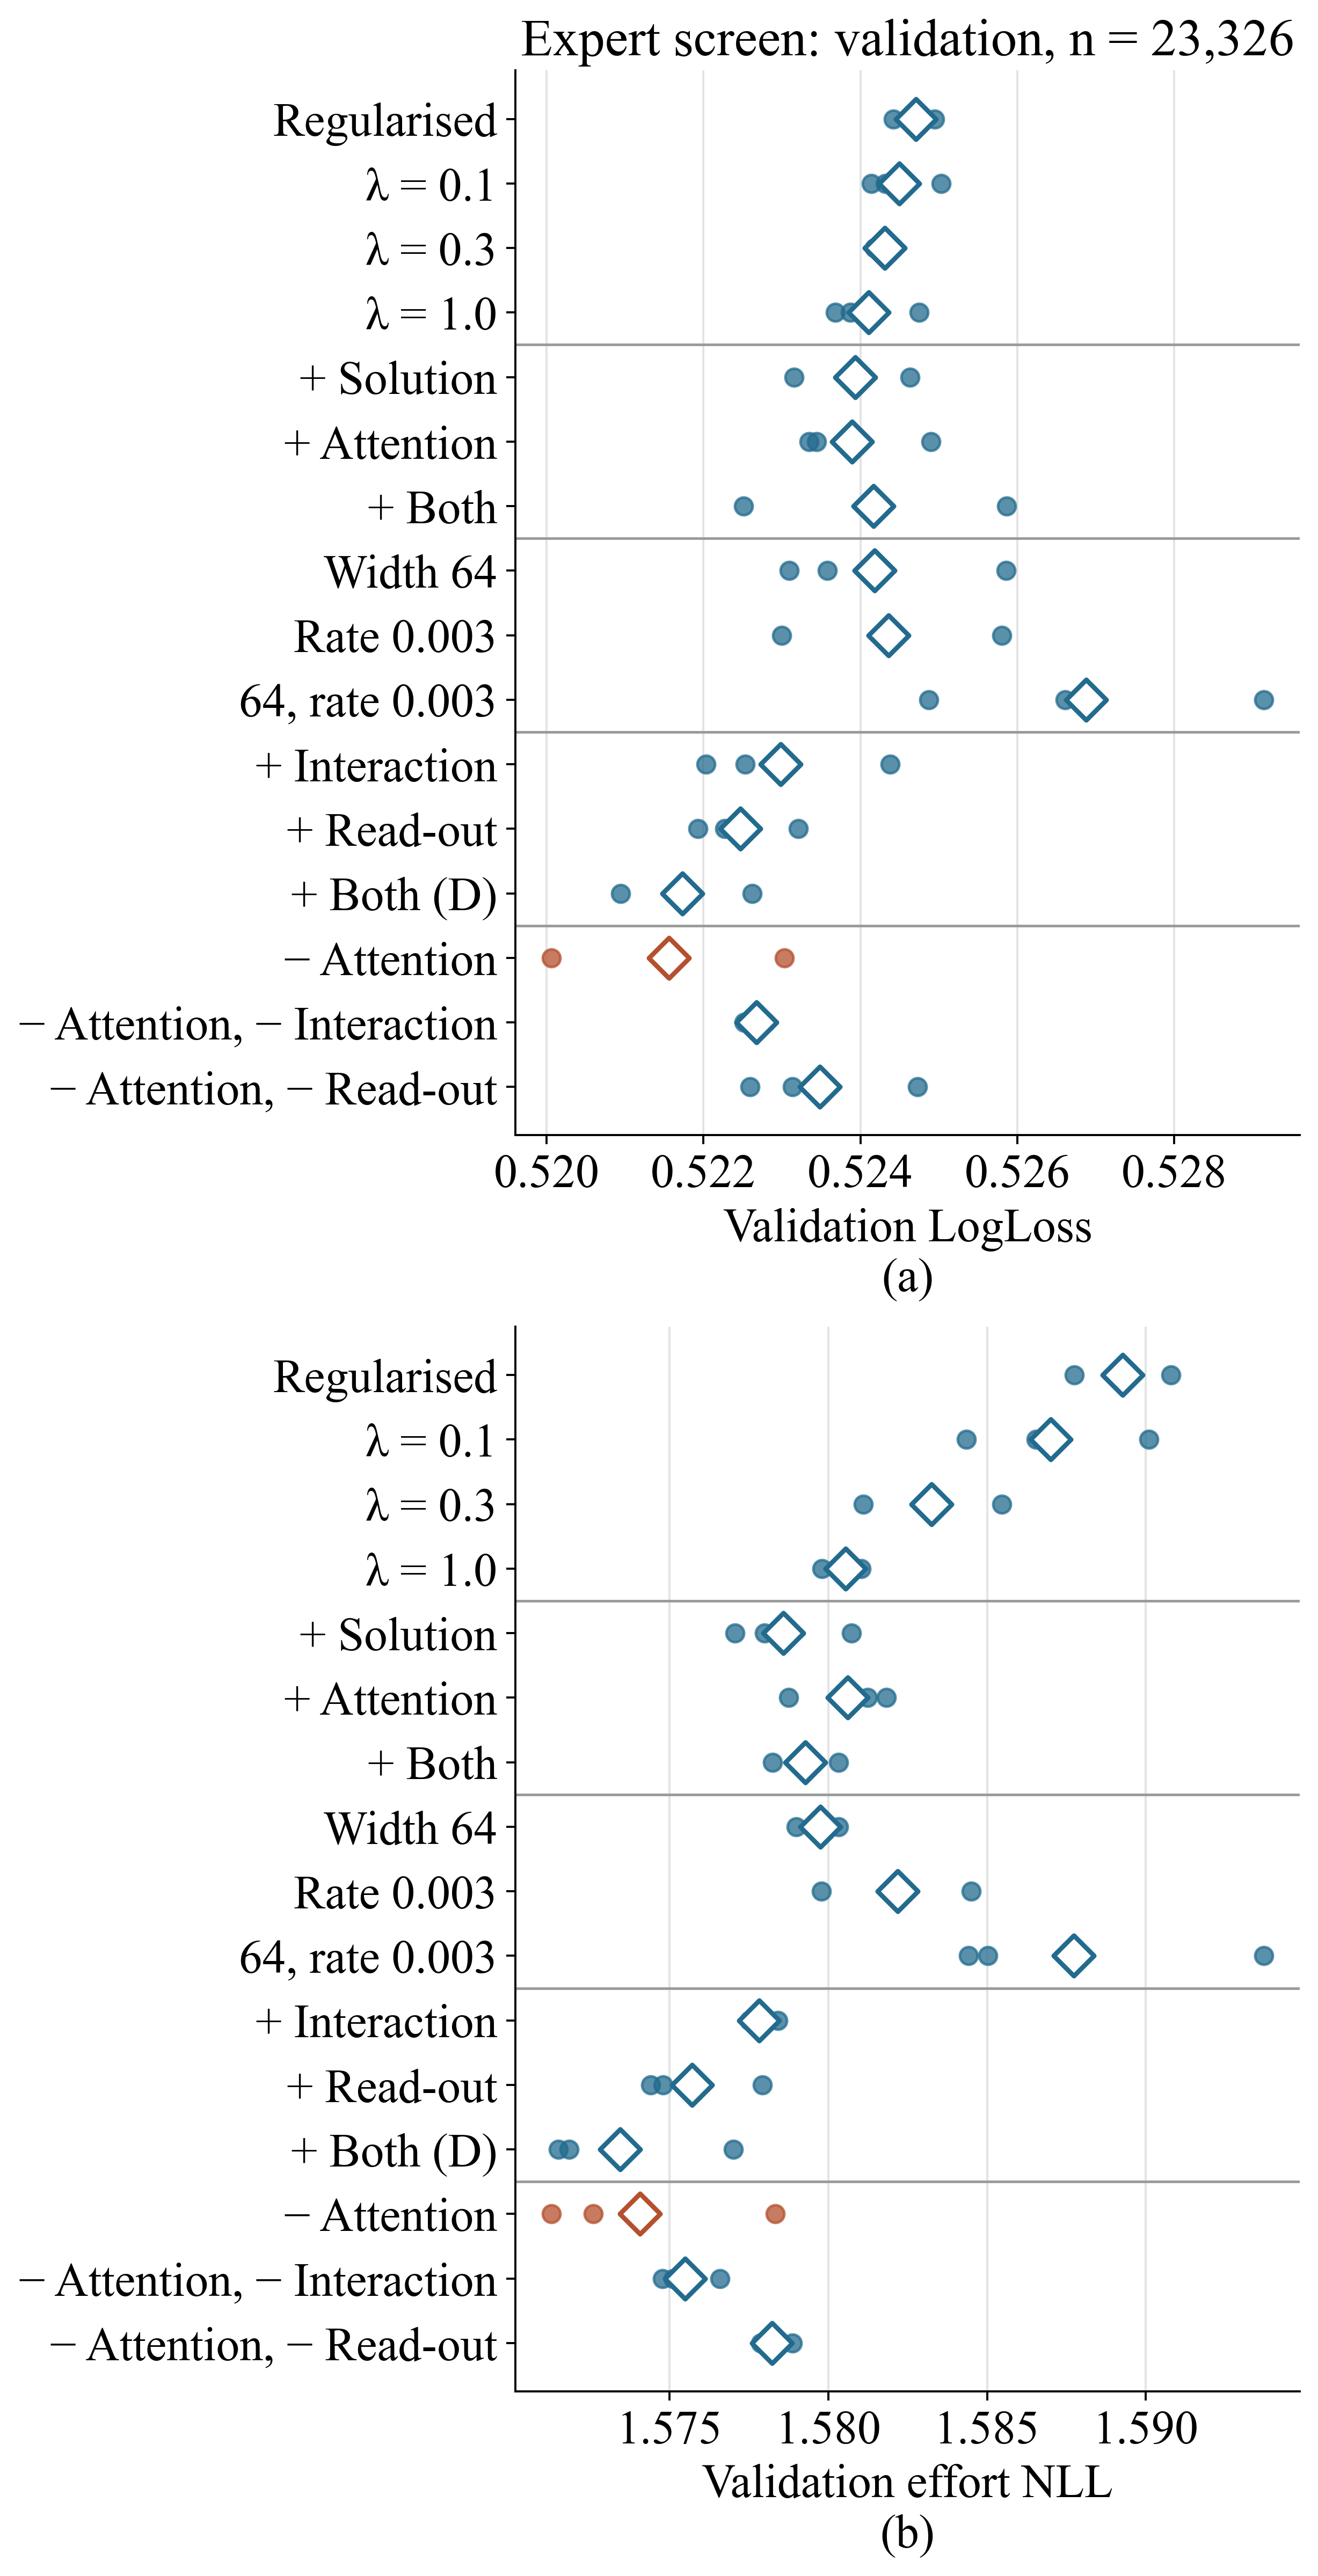

In [12]:
SHORT_LABELS = {
    "Regularised, λ = 0.1": "Regularised",
    "Unregularised, λ = 0.1": "λ = 0.1",
    "Unregularised, λ = 0.3": "λ = 0.3",
    "Unregularised, λ = 1.0": "λ = 1.0",
    "+ Solution graph": "+ Solution",
    "+ Task attention": "+ Attention",
    "+ Solution-conditioned attention": "+ Both",
    "Width 64": "Width 64",
    "Learning rate 0.003": "Rate 0.003",
    "Width 64, learning rate 0.003": "64, rate 0.003",
    "+ Interaction embedding": "+ Interaction",
    "+ Task read-out": "+ Read-out",
    "+ Interaction embedding and task read-out": "+ Both (D)",
}
order = list(dict.fromkeys(screen.Candidate))
fig, axes = plt.subplots(2, 1, figsize=(6.9, 13.6), layout="constrained")
for ax, metric, label, letter in zip(
    axes,
    ["LogLoss", "Effort_NLL"],
    ["Validation LogLoss", "Validation effort NLL"],
    ["a", "b"],
):
    for position, candidate in enumerate(order):
        values = screen.loc[screen.Candidate.eq(candidate), metric]
        color = "#B5502E" if candidate == selected_label else "#236B8E"
        ax.scatter(
            values,
            np.full(len(values), position),
            s=46,
            color=color,
            alpha=0.75,
            zorder=3,
        )
        ax.scatter(
            values.mean(),
            position,
            s=120,
            marker="D",
            facecolor="white",
            edgecolor=color,
            linewidth=1.8,
            zorder=4,
        )
    stage_sizes = [len(stage_a_mean), len(stage_b_mean), len(stage_c_mean)]
    if stage_f_frames:
        stage_sizes.append(len(stage_d_mean))
    for boundary in np.cumsum(stage_sizes):
        ax.axhline(boundary - 0.5, color="#9A9A9A", linewidth=1.0)
    ax.set_yticks(
        range(len(order)),
        [
            SHORT_LABELS.get(
                name,
                name.replace("Task attention", "Attention")
                .replace("Interaction embedding", "Interaction")
                .replace("Task read-out", "Read-out")
                .replace("Solution graph", "Solution"),
            )
            for name in order
        ],
    )
    ax.invert_yaxis()
    ax.set_xlabel(f"{label}\n({letter})")
    ax.grid(axis="x", color="#E3E3E3", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_title(f"Expert screen: validation, n = {len(validation_data):,}")
save_figure(fig, "05_screen")
plt.show()

**Interpretation.** Removing dropout and weight decay and raising the auxiliary weight lowered the three-seed mean validation LogLoss of the expert step by step, from 0.52471 for the regularised configuration to 0.52410 at λ = 1.0, and the joint effort NLL from 1.58927 to 1.58054; λ = 1.0 became the incumbent. In stage B, target-conditioned attention lowered LogLoss by a further 0.00021 and met the 0.0002 rule. The reference-solution graph lowered it by 0.00017 and missed the rule, although it gave the lowest effort NLL of stages A–C (1.57858); combining both modules widened the spread across seeds (SD 0.00168) without a gain. Stage C did not improve on the stage-B selection: width 64 (0.52418) and learning rate 0.003 (0.52436) were worse, and their combination was unstable (0.52688).

Stage D gave the largest step of the screen. The interaction embedding alone reached 0.52298 and the task read-out alone 0.52247; together they reached 0.52173, 0.00216 below the stage-B selection, with the effort NLL falling to 1.57344. In the backward check (stage F), removing the attention module did not raise the criterion (0.52156, a change of −0.00017), so the module was removed. From the resulting configuration, removing the interaction embedding raised LogLoss by 0.00111 and removing the task read-out by 0.00192; both were retained.

The selected configuration is the unregularised expert with λ = 1.0, the interaction embedding and the task read-out, without the attention module and without the reference-solution graph. Its validation LogLoss is 0.00315 below the regularised starting point. The seed standard deviations (0.0001–0.0015) are smaller than the stage-D gain but of the same order as the stage-B and stage-F differences, so those two decisions establish a direction, not a large effect; the three-seed ablations of notebook 07 examine the retained modules with learner-level intervals.

## Selected expert architecture

The diagram is generated from the configuration selected by the screen. Learner programs pass through the program-graph encoder; every prior attempt also contributes its process descriptors and an embedding of its task and observed outcome state; the GRU summarises the ordered attempts. The target task is represented by its context vector (aggregates, task descriptors and task identity), and the two heads read the shared representation with task-specific weights. The reference-solution graph was not adopted in stage B and the target-conditioned attention was removed by the backward check, so neither appears. Arrows show inputs observed before the current first run; target labels enter only the loss functions.

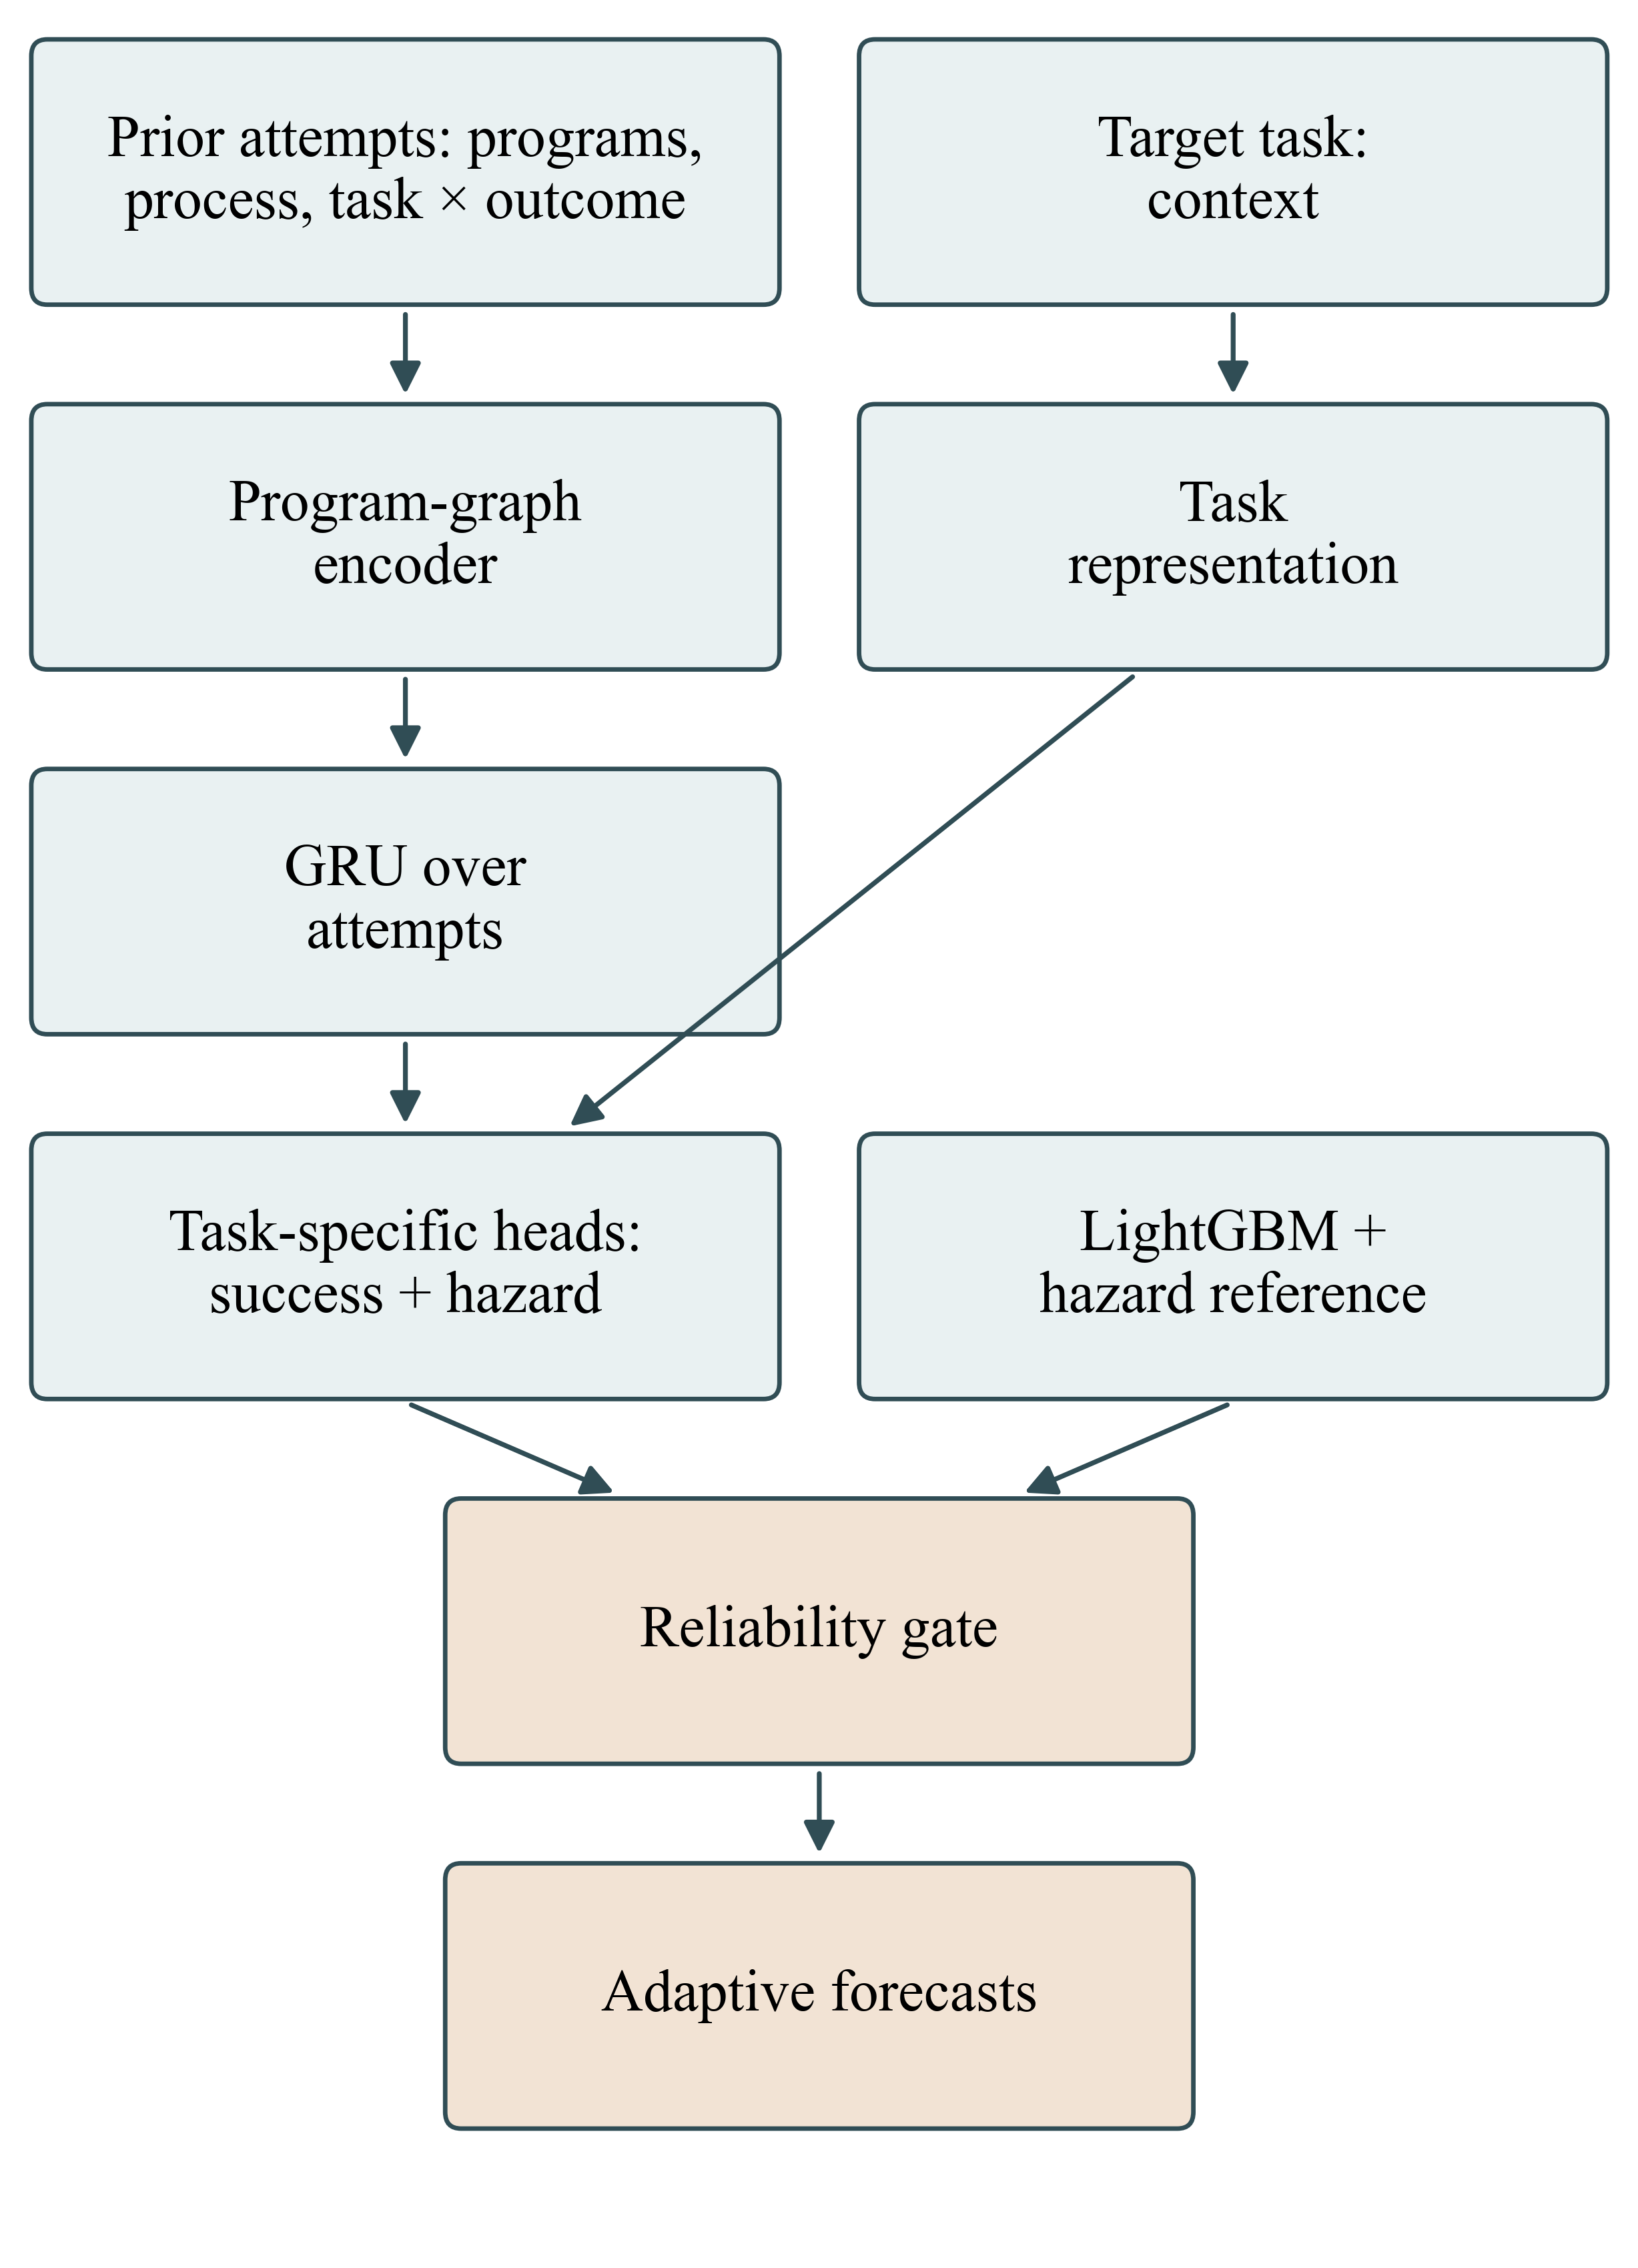

In [13]:
def draw_box(ax, x, y, width, height, label, accent=False):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            width,
            height,
            boxstyle="round,pad=0.10",
            facecolor="#F2E3D4" if accent else "#E9F1F2",
            edgecolor="#304D55",
            linewidth=1.4,
        )
    )
    ax.text(
        x + width / 2, y + height / 2, label, ha="center", va="center", fontsize=18
    )


def draw_arrow(ax, start, end):
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle="-|>",
            mutation_scale=20,
            color="#304D55",
            linewidth=1.5,
        )
    )


fig, ax = plt.subplots(figsize=(6.9, 9.6), layout="constrained")
ax.set(xlim=(0, 10), ylim=(0, 13.4))
ax.axis("off")
LEFT, RIGHT, WIDTH, HEIGHT = 0.15, 5.35, 4.5, 1.4
CENTRE = 2.75
ROWS = [11.8, 9.6, 7.4, 5.2, 3.0, 0.8]
left_mid, right_mid = LEFT + WIDTH / 2, RIGHT + WIDTH / 2
draw_box(
    ax,
    LEFT,
    ROWS[0],
    WIDTH,
    HEIGHT,
    "Prior attempts: programs,\nprocess, task × outcome"
    if FULL_CONFIG.use_interaction
    else "Prior attempts:\nprograms + process",
)
draw_box(
    ax,
    RIGHT,
    ROWS[0],
    WIDTH,
    HEIGHT,
    "Target task:\nsolution + context"
    if FULL_CONFIG.use_solution
    else "Target task:\ncontext",
)
draw_box(
    ax,
    LEFT,
    ROWS[1],
    WIDTH,
    HEIGHT,
    "Program-graph\nencoder"
    if FULL_CONFIG.use_code
    else "Process\nprojection",
)
draw_box(ax, RIGHT, ROWS[1], WIDTH, HEIGHT, "Task\nrepresentation", FULL_CONFIG.use_solution)
draw_box(
    ax,
    LEFT,
    ROWS[2],
    WIDTH,
    HEIGHT,
    "GRU over\nattempts" if FULL_CONFIG.use_recurrence else "Order-free\npooling",
)
if FULL_CONFIG.use_task_attention:
    draw_box(
        ax, RIGHT, ROWS[2], WIDTH, HEIGHT, "Target-conditioned\nattention", True
    )
draw_box(
    ax,
    LEFT,
    ROWS[3],
    WIDTH,
    HEIGHT,
    "Task-specific heads:\nsuccess + hazard"
    if FULL_CONFIG.use_task_readout
    else "Expert heads:\nsuccess + hazard",
)
draw_box(ax, RIGHT, ROWS[3], WIDTH, HEIGHT, "LightGBM +\nhazard reference")
draw_box(ax, CENTRE, ROWS[4], WIDTH, HEIGHT, "Reliability gate", True)
draw_box(ax, CENTRE, ROWS[5], WIDTH, HEIGHT, "Adaptive forecasts", True)
gap = 0.12
draw_arrow(ax, (left_mid, ROWS[0] - gap), (left_mid, ROWS[1] + HEIGHT + gap))
draw_arrow(ax, (right_mid, ROWS[0] - gap), (right_mid, ROWS[1] + HEIGHT + gap))
if FULL_CONFIG.use_solution:
    # The reference solution is encoded with the shared program-graph weights.
    draw_arrow(
        ax,
        (LEFT + WIDTH + gap, ROWS[1] + HEIGHT / 2),
        (RIGHT - gap, ROWS[1] + HEIGHT / 2),
    )
draw_arrow(ax, (left_mid, ROWS[1] - gap), (left_mid, ROWS[2] + HEIGHT + gap))
if FULL_CONFIG.use_task_attention:
    draw_arrow(ax, (right_mid, ROWS[1] - gap), (right_mid, ROWS[2] + HEIGHT + gap))
    draw_arrow(
        ax,
        (LEFT + WIDTH + gap, ROWS[2] + HEIGHT / 2),
        (RIGHT - gap, ROWS[2] + HEIGHT / 2),
    )
    draw_arrow(
        ax,
        (right_mid - 0.6, ROWS[2] - gap),
        (left_mid + 1.0, ROWS[3] + HEIGHT + gap),
    )
else:
    draw_arrow(
        ax,
        (right_mid - 0.6, ROWS[1] - gap),
        (left_mid + 1.0, ROWS[3] + HEIGHT + gap),
    )
draw_arrow(ax, (left_mid, ROWS[2] - gap), (left_mid, ROWS[3] + HEIGHT + gap))
draw_arrow(ax, (left_mid, ROWS[3] - gap), (CENTRE + 1.0, ROWS[4] + HEIGHT + gap))
draw_arrow(
    ax, (right_mid, ROWS[3] - gap), (CENTRE + WIDTH - 1.0, ROWS[4] + HEIGHT + gap)
)
draw_arrow(
    ax, (CENTRE + WIDTH / 2, ROWS[4] - gap), (CENTRE + WIDTH / 2, ROWS[5] + HEIGHT + gap)
)
save_figure(fig, "05_selected_architecture")
plt.show()

## Training the structural-temporal expert

The selected configuration is trained for 8 epochs with batch size 256 and AdamW, with two message-passing rounds; its width and learning rate are those chosen by the screen (see the configuration table below). The number of epochs equals that of the sequential comparators. Graphs are limited to 64 nodes; the effect of truncation is described by the coverage tables above. Training on three learner-disjoint folds produces the out-of-fold inputs for fusion. The curves show optimisation but do not replace an assessment of generalisation.

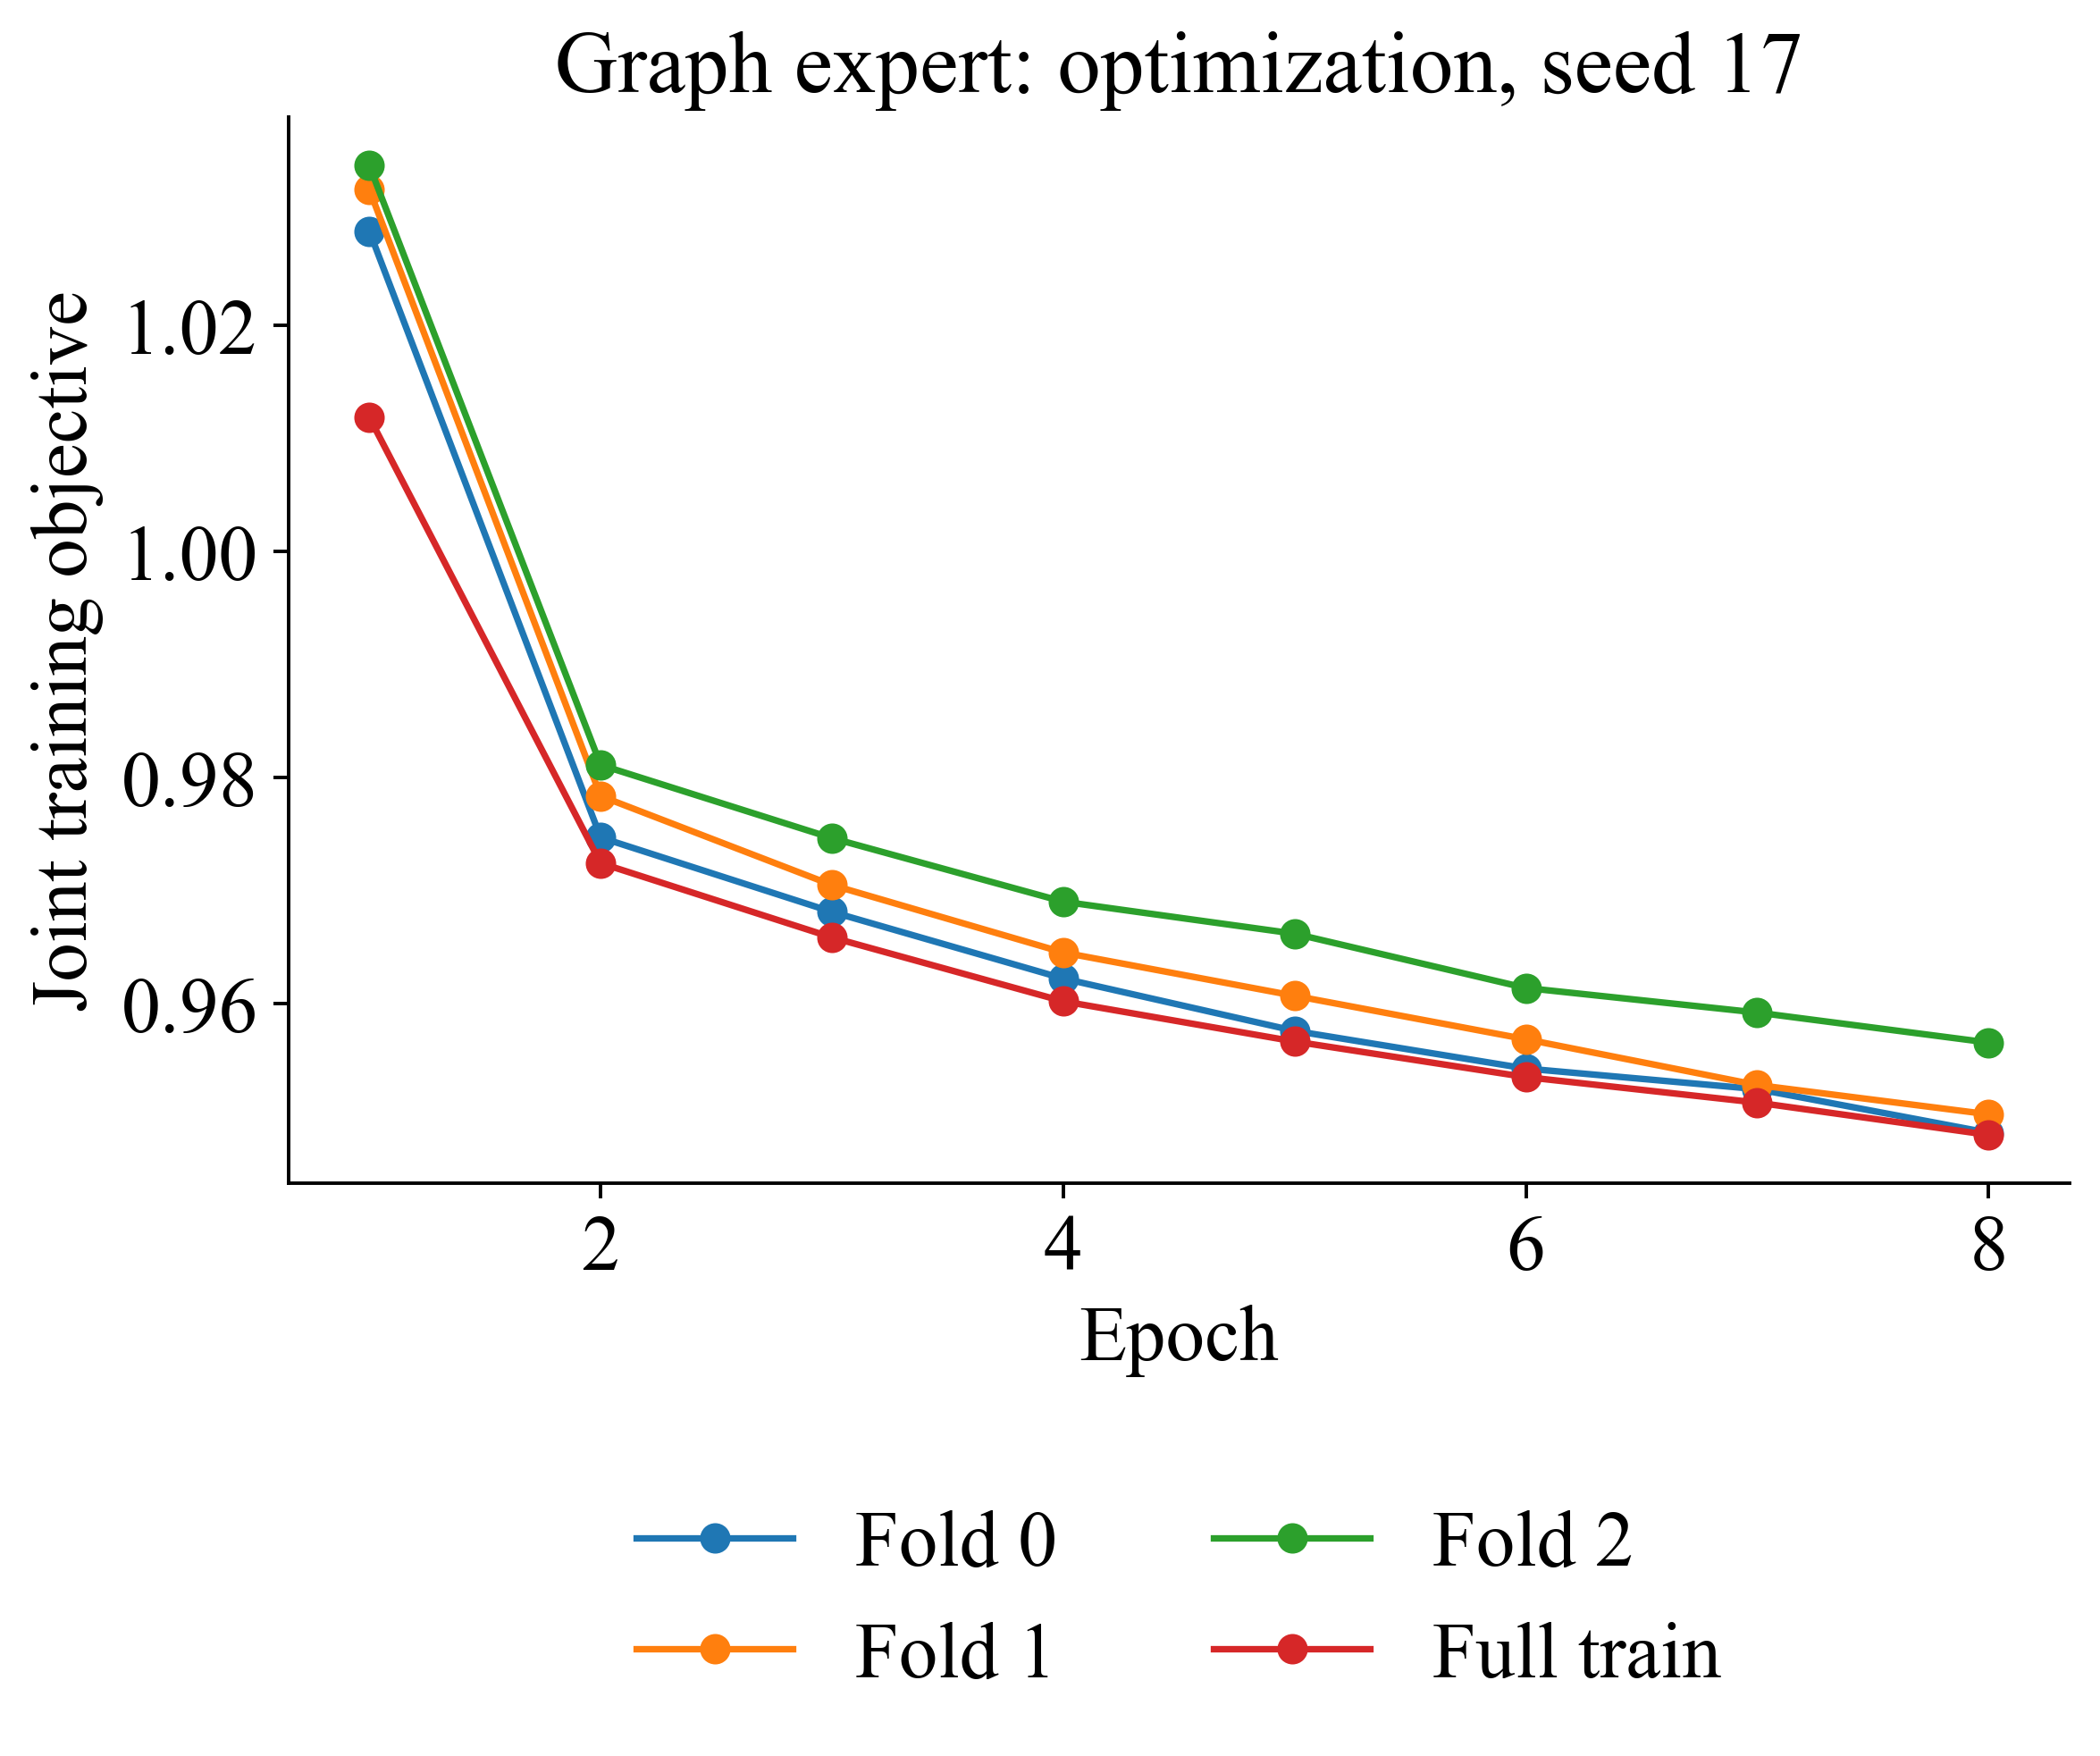

In [14]:
train_component("FullGraph", FULL_CONFIG, SEEDS[0])
curves_frame = pd.DataFrame(graph_curves)
curves_frame = curves_frame[
    curves_frame.Variant.eq("FullGraph") & curves_frame.Seed.eq(SEEDS[0])
]
fig, ax = plt.subplots(figsize=(6.6, 5.5), layout="constrained")
for run, group in curves_frame.groupby("Run", sort=False):
    ax.plot(group.Epoch, group["Training objective"], marker="o", label=run)
ax.set(
    xlabel="Epoch",
    ylabel="Joint training objective",
    title="Graph expert: optimization, seed 17",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False
)
save_figure(fig, "05_graph_learning_curves")
plt.show()

## Control for censored effort

A tree-based conditional intensity model is trained on success events and the number of observed unsuccessful runs. Incomplete attempts are not converted into a known time to success. The table compares the joint likelihood of the graph expert and the selected base with this strong auxiliary control.

The name of the base model remains the same as in notebook 03/04; in all effort comparisons, its prediction is supplemented by the common hazard control.


In [15]:
train_hazard(SEEDS[0])
base_oof, graph_oof, base_valid, graph_valid = paired_components(
    "FullGraph", SEEDS[0]
)
joint_controls = [
    record_joint_metrics(BASE_NAME, SEEDS[0], base_valid),
    record_joint_metrics("GraphTrajectory", SEEDS[0], graph_valid),
]
table(
    pd.DataFrame(joint_controls)[
        ["Model", "Split", "n", "Seed", "Effort_NLL"]
    ],
    "Joint NLL of observed runs ↓",
    "05_joint_controls",
)
save_experiment_state()

Joint NLL of observed runs ↓

,Model,Split,n,Seed,Effort_NLL
0,LightGBM,Validation,23326,17,1.59332
1,GraphTrajectory,Validation,23326,17,1.57127


## Sensitivity of adaptive fusion

Eight inexpensive configurations explore the L2 penalty on the gate coefficients (0, 0.0001, 0.001, 0.01) and the prior expert weight towards which the penalty shrinks (0.2, 0.5); with a zero penalty the prior only sets the starting point of the optimiser. The components are not retrained. The selection criterion is validation LogLoss. The dependence on these settings must be visible regardless of whether quality improves.

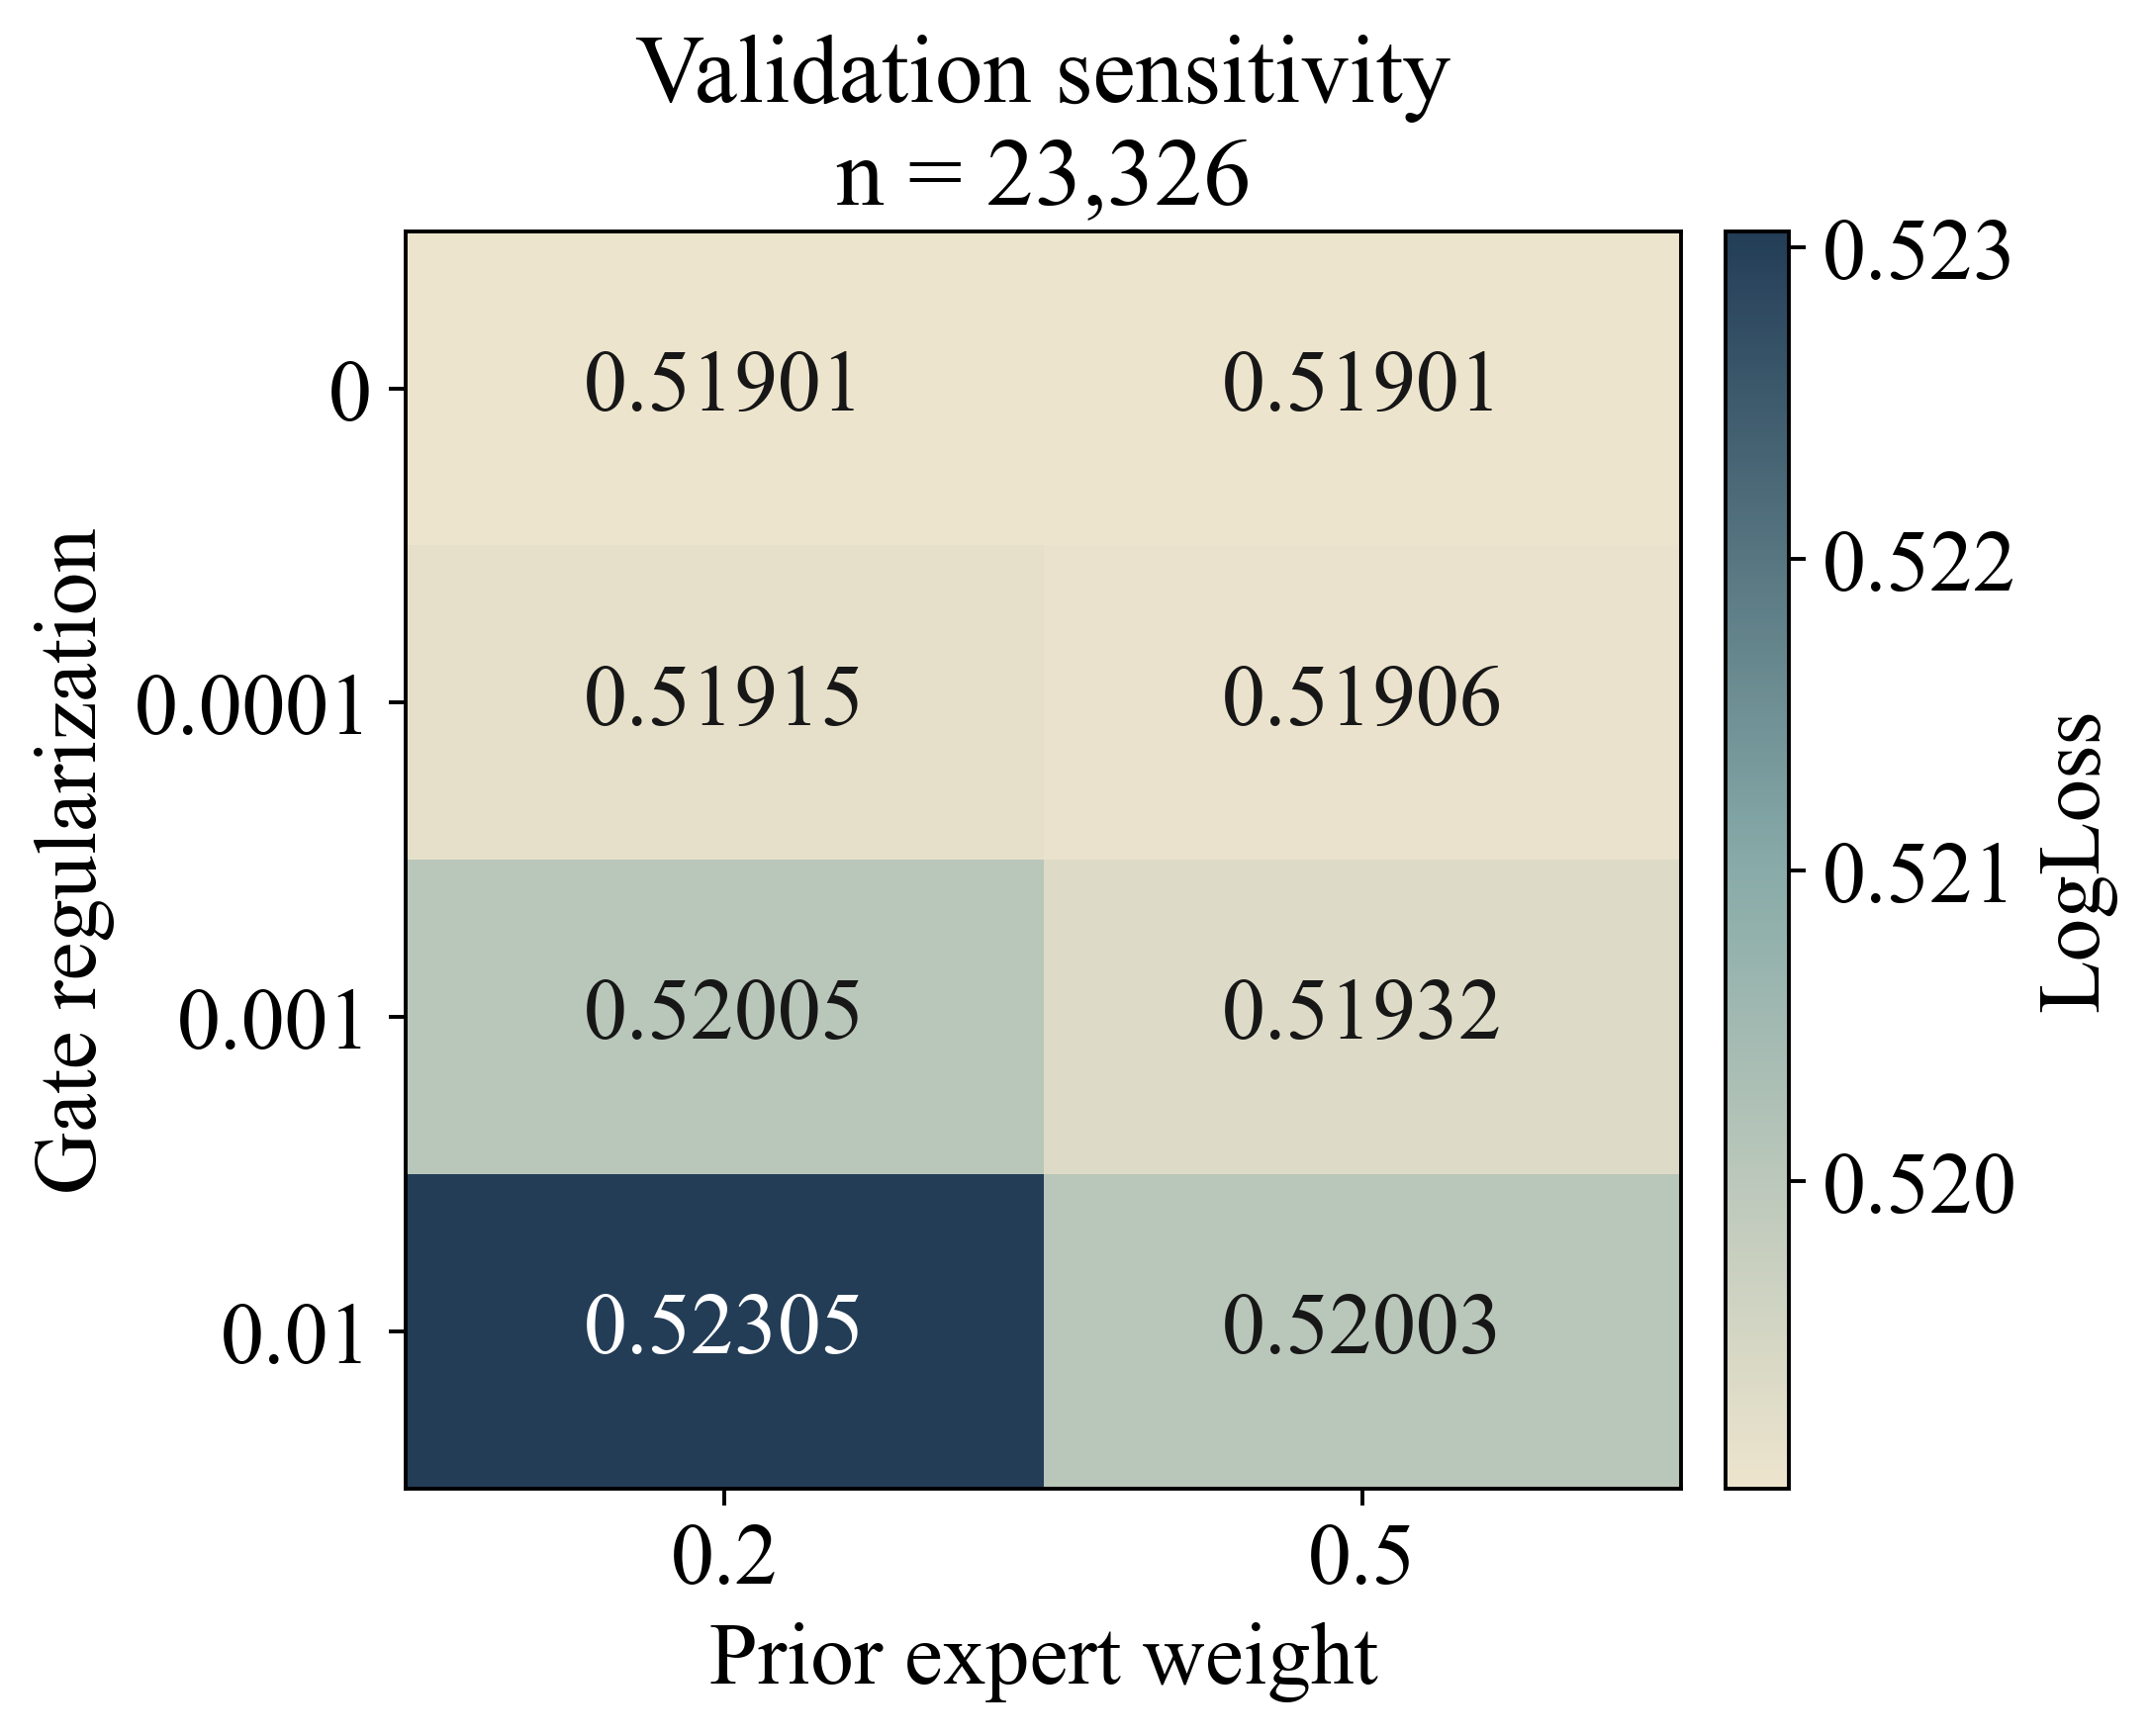

In [16]:
gate_grid, chosen_gate = evaluate_gate_grid(
    base_oof, graph_oof, base_valid, graph_valid, FULL_CONFIG.auxiliary_weight
)
gate_grid.to_csv(ROOT / "Tables/05_gate_sensitivity.csv", index=False)
gate_results[("AlphaProg-AGMT", SEEDS[0])] = chosen_gate
landscape = gate_grid.pivot(
    index="Regularization", columns="Prior weight", values="LogLoss"
)
fig, ax = plt.subplots(figsize=(6.1, 4.9), layout="constrained")
from matplotlib.colors import LinearSegmentedColormap

artist = ax.imshow(
    landscape.to_numpy(),
    aspect="auto",
    cmap=LinearSegmentedColormap.from_list(
        "alpha_gate", ["#EDE4CD", "#87AAA8", "#233D57"]
    ),
)
ax.set_xticks(
    range(landscape.shape[1]), [f"{value:g}" for value in landscape.columns]
)
ax.set_yticks(
    range(landscape.shape[0]), [f"{value:g}" for value in landscape.index]
)
for i in range(landscape.shape[0]):
    for j in range(landscape.shape[1]):
        rgba = artist.cmap(artist.norm(landscape.iloc[i, j]))
        bright = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            j,
            i,
            f"{landscape.iloc[i,j]:.5f}",
            ha="center",
            va="center",
            fontsize=18,
            color="white" if bright < 0.5 else "#171717",
        )
ax.set(
    xlabel="Prior expert weight",
    ylabel="Gate regularization",
    title=f"Validation sensitivity\nn = {len(validation_data):,}",
)
fig.colorbar(artist, ax=ax, label="LogLoss", fraction=0.05, pad=0.035)
save_figure(fig, "05_gate_sensitivity")
plt.show()
save_experiment_state()

**Interpretation.** For the selected expert, validation LogLoss rises with the gate penalty: 0.51901 at L2 = 0, 0.51906–0.51915 at 0.0001, 0.51932–0.52005 at 0.001 and 0.52003–0.52305 at 0.01. Without a penalty both priors reach the same optimum (they differ only in the starting point), so L2 = 0 is fixed; the recorded prior 0.5 has no effect at this setting.

## Gate coefficients for new tasks

The gate above is fitted on forecasts for tasks that are present in the training data, and none of its eight cues signals that a task is new. Stage E of the registered screen therefore examines the gate on task-held-out forecasts. The tasks are divided into three folds stratified by curriculum section. For every pair of a learner fold and a task fold, the reference and the expert are fitted on the other learner folds without the tasks of the task fold and predict the held-out learners on the held-out tasks, whose identifier is replaced by the unknown index. The validation queries of each task fold are predicted by models fitted on all training queries of the other tasks. Three gates are compared on these validation forecasts: the single gate applied unchanged, one additional intercept coefficient for new tasks, and a second coefficient vector over the same cues for new tasks. The coefficients for known tasks are not refitted, so forecasts for known tasks do not change; a candidate is adopted only if it lowers the validation LogLoss for new tasks by at least 0.0002.

In [17]:
novel_train = novel_task_forecasts(FULL_CONFIG, SEEDS[0], "NewTasks")
novel_validation = novel_task_forecasts(
    FULL_CONFIG, SEEDS[0], "NewTasks", validation_data, history_validation
)
novelty_table, NOVELTY_MODE, novel_coefficients = evaluate_novelty_gates(
    chosen_gate, novel_train, novel_validation, FULL_CONFIG.auxiliary_weight
)
chosen_gate["novelty_mode"] = NOVELTY_MODE
chosen_gate["novel_coefficients"] = novel_coefficients
table(
    novelty_table,
    "Forecasts for tasks without training data: validation queries predicted "
    "by models fitted without their task (seed 17); LogLoss, Brier and effort "
    "NLL ↓, AUROC and AP ↑",
    "05_novelty_gate",
)
save_experiment_state()

Forecasts for tasks without training data: validation queries predicted by models fitted without their task (seed 17); LogLoss, Brier and effort NLL ↓, AUROC and AP ↑

,Forecast for new tasks,Mean expert weight,LogLoss,AUROC,AP,Brier,Effort_NLL,Selected
0,Reference only,0.00000,0.62957,0.69625,0.63147,0.22022,1.80519,No
1,Expert only,1.00000,0.60905,0.71693,0.64601,0.21185,1.72952,No
2,Single gate,0.65653,0.60335,0.72379,0.65526,0.20955,1.72766,No
3,Novelty offset,0.63931,0.60329,0.72390,0.65545,0.20953,1.72823,No
4,Novelty-specific gate,0.75512,0.60098,0.72660,0.65771,0.20836,1.71989,Yes


**Interpretation.** On tasks withheld from training, the reference loses most of its accuracy (validation LogLoss 0.62957) and the expert alone reaches 0.60905. The single gate, fitted for known tasks, already improves on the expert (0.60335) with a mean expert weight of 0.66. One additional intercept for new tasks changes little (0.60329). A separate coefficient vector for new tasks lowers LogLoss to 0.60098, 0.00237 below the single gate and 0.00806 below the expert alone, raises the mean expert weight to 0.76 and also gives the lowest effort NLL (1.71989). It meets the 0.0002 rule and is adopted. These forecasts come from seed 17 and from the validation partition; the unseen-task scheme of notebook 07 repeats the comparison on the test learners with three seeds.

## Selected configuration

Only the final setting for the subsequent seeds is fixed here. The expert configuration was selected by the screen and the gate penalty and prior by the previous figure; the remaining values were set before training. Changing them on the basis of the locked test is not permitted.

In [18]:
configuration_rows = [
    ["Base predictor", BASE_NAME],
    ["Graph width", FULL_CONFIG.width],
    ["Graph steps", FULL_CONFIG.graph_steps],
    ["History limit", GRAPH_HISTORY],
    ["Raw history channels", len(PROCESS_COLUMNS)],
    ["History task descriptors", len(HISTORY_TASK_FEATURES)],
    ["Node limit", FULL_CONFIG.max_nodes],
    ["Epochs", GRAPH_EPOCHS],
    ["Learning rate", FULL_CONFIG.learning_rate],
    ["Auxiliary weight", FULL_CONFIG.auxiliary_weight],
    ["Weight decay", FULL_CONFIG.weight_decay],
    ["Dropout", FULL_CONFIG.dropout],
    ["Reference-solution graph", "Yes" if FULL_CONFIG.use_solution else "No"],
    [
        "Target-conditioned attention",
        f"{FULL_CONFIG.attention_heads} heads"
        if FULL_CONFIG.use_task_attention
        else "No",
    ],
    ["Interaction embedding", "Yes" if FULL_CONFIG.use_interaction else "No"],
    ["Task read-out", "Yes" if FULL_CONFIG.use_task_readout else "No"],
    ["Gate L2", chosen_gate["regularization"]],
    ["Gate prior", chosen_gate["prior_weight"]],
    ["Gate for new tasks", NOVELTY_MODE],
    ["Screen selection", selected_label],
]
configuration_table = pd.DataFrame(
    configuration_rows, columns=["Parameter", "Value"]
)
configuration_table.insert(0, "Model", "AlphaProg-AGMT")
table(
    configuration_table,
    "Fixed configuration",
    "05_selected_configuration",
)

Fixed configuration

,Model,Parameter,Value
0,AlphaProg-AGMT,Base predictor,LightGBM
1,AlphaProg-AGMT,Graph width,32
2,AlphaProg-AGMT,Graph steps,2
3,AlphaProg-AGMT,History limit,32
4,AlphaProg-AGMT,Raw history channels,30
5,AlphaProg-AGMT,History task descriptors,8
6,AlphaProg-AGMT,Node limit,64
7,AlphaProg-AGMT,Epochs,8
8,AlphaProg-AGMT,Learning rate,0.001
9,AlphaProg-AGMT,Auxiliary weight,1.0


## Reproducibility of the full model

The main model is evaluated with seeds 17, 42 and 2026. For the additional seeds, the already selected gate configuration is retained. Each seed receives its own OOF predictions of the components. The spread across seeds does not replace a confidence interval over independent learners.

In [19]:
record_joint_metrics(
    "AlphaProg-AGMT", SEEDS[0], chosen_gate["validation_probability"]
)
for seed in SEEDS[1:]:
    train_component("FullGraph", FULL_CONFIG, seed)
    train_hazard(seed)
    fitted_gate = fit_fixed_gate("FullGraph", seed, chosen_gate)
    fitted_gate["novelty_mode"] = NOVELTY_MODE
    fitted_gate["novel_coefficients"] = None
    if NOVELTY_MODE != "Single gate":
        novel_seed = novel_task_forecasts(FULL_CONFIG, seed, "NewTasks")
        fitted_gate["novel_coefficients"] = fit_novel_regime(
            fitted_gate,
            train_data,
            novel_seed["base"],
            novel_seed["graph"],
            NOVELTY_MODE,
            FULL_CONFIG.auxiliary_weight,
        )
    gate_results[("AlphaProg-AGMT", seed)] = fitted_gate
    _, _, reference_probability, expert_probability = paired_components(
        "FullGraph", seed
    )
    record_joint_metrics(BASE_NAME, seed, reference_probability)
    record_joint_metrics("GraphTrajectory", seed, expert_probability)
    record_joint_metrics(
        "AlphaProg-AGMT", seed, fitted_gate["validation_probability"]
    )
    save_experiment_state()
joint_metrics = pd.DataFrame(experiment_rows)
probability_summary = (
    joint_metrics.groupby(["Model", "Split", "n"], sort=False)
    .agg(
        LogLoss=("LogLoss", "mean"),
        Seed_SD=("LogLoss", "std"),
        Brier=("Brier", "mean"),
    )
    .reset_index()
)
table(
    probability_summary,
    "Probabilistic quality; LogLoss and Brier ↓",
    "05_probability_quality",
)

Probabilistic quality; LogLoss and Brier ↓

,Model,Split,n,LogLoss,Seed_SD,Brier
0,LightGBM,Validation,23326,0.53074,0.00021,0.17833
1,GraphTrajectory,Validation,23326,0.52156,0.00149,0.17502
2,AlphaProg-AGMT,Validation,23326,0.51971,0.00062,0.17446


**Interpretation.** Over seeds 17, 42 and 2026, AlphaProg-AGMT reaches a mean validation LogLoss of 0.51971 (seed SD 0.00062), against 0.52156 for its own expert and 0.53074 for the LightGBM reference; Brier falls from 0.17833 to 0.17446. The gain of the fusion over its expert is 0.00186, and the seed spread of the fused forecast is smaller than that of the expert (0.00149). Validation was used for selection, so these values are optimistic; the locked test in notebook 06 is the evaluation of record.

## Ranking and the additional task

AUROC and AP characterise the ranking of first success. The joint NLL additionally accounts for observed effort and censoring. These are different properties; success on one of them is not declared superiority on all metrics.

In [20]:
secondary_summary = (
    joint_metrics.groupby(["Model", "Split", "n"], sort=False)
    .agg(
        AUROC=("AUROC", "mean"),
        AP=("AP", "mean"),
        Effort_NLL=("Effort_NLL", "mean"),
    )
    .reset_index()
)
table(
    secondary_summary, "AUROC and AP ↑; joint NLL ↓", "05_secondary_quality"
)

AUROC and AP ↑; joint NLL ↓

,Model,Split,n,AUROC,AP,Effort_NLL
0,LightGBM,Validation,23326,0.80477,0.73935,1.59297
1,GraphTrajectory,Validation,23326,0.81192,0.74532,1.57406
2,AlphaProg-AGMT,Validation,23326,0.81315,0.74757,1.57062


**Interpretation.** The ranking metrics move in the same direction: AUROC 0.81315 and AP 0.74757 for AlphaProg-AGMT versus 0.80477 and 0.73935 for LightGBM and 0.81192 and 0.74532 for the expert. For the joint effort target, the NLL is 1.57062 versus 1.59297 for LightGBM with the hazard companion and 1.57406 for the expert; the fusion therefore improves the secondary target as well as the first run.

## Mechanism ablations

All ablations use seed 17 and the same queries; the number of epochs and the width remain the same. NoGraphEncoder removes the graph module for learner programs and reference solutions, while the common tabular code summaries are retained. NoOrder replaces the GRU with order-free episode states. NoAuxLoss excludes the auxiliary loss; its untrained head is not used, and the effort prediction is taken from the common tree-based control. NoEdges retains the active parameters and disables topological messages. NoInteraction removes the embedding of prior tasks with their outcomes, and NoTaskReadout removes the task-specific read-out. NoSolutionGraph and NoTaskAttention are produced only when these modules belong to the selected configuration, which is not the case here.

ConstantFusion is a trainable constant weight selected from the same gate settings. The best single component is selected by validation LogLoss. The architectural ablations use the gate settings of the full model; they assess the contribution of the components under this protocol and do not replace a full search for each architecture.

In [21]:
ablation_rows = []
full_row = (
    joint_metrics[
        (joint_metrics.Model.eq("AlphaProg-AGMT"))
        & joint_metrics.Seed.eq(SEEDS[0])
    ]
    .iloc[0]
    .to_dict()
)
ablation_rows.append(full_row)
for variant, configuration in VARIANT_CONFIGS.items():
    train_component(variant, configuration, SEEDS[0])
    fitted_gate = fit_fixed_gate(variant, SEEDS[0], chosen_gate)
    gate_results[(variant, SEEDS[0])] = fitted_gate
    ablation_rows.append(
        record_joint_metrics(
            variant, SEEDS[0], fitted_gate["validation_probability"]
        )
    )
    save_experiment_state()
constant_grid, constant_gate = evaluate_gate_grid(
    base_oof,
    graph_oof,
    base_valid,
    graph_valid,
    FULL_CONFIG.auxiliary_weight,
    adaptive=False,
)
gate_results[("ConstantFusion", SEEDS[0])] = constant_gate
ablation_rows.append(
    record_joint_metrics(
        "ConstantFusion", SEEDS[0], constant_gate["validation_probability"]
    )
)
single_name, single_probability = min(
    [(BASE_NAME, base_valid), ("GraphTrajectory", graph_valid)],
    key=lambda item: log_loss(validation_data.y, item[1][:, 0]),
)
ablation_rows.append(
    record_joint_metrics(
        "BestSingle: " + single_name, SEEDS[0], single_probability
    )
)
ablation_table = pd.DataFrame(ablation_rows)
ablation_table["Delta_LogLoss"] = ablation_table.LogLoss - full_row["LogLoss"]
ablation_table.to_csv(ROOT / "Tables/05_all_ablation_metrics.csv", index=False)
table(
    ablation_table[["Model", "Split", "n", "LogLoss", "Delta_LogLoss"]],
    "Ablations: LogLoss ↓; a positive Δ indicates deterioration relative to the full model",
    "05_ablation_primary",
)
save_experiment_state()

Ablations: LogLoss ↓; a positive Δ indicates deterioration relative to the full model

,Model,Split,n,LogLoss,Delta_LogLoss
0,AlphaProg-AGMT,Validation,23326,0.51901,0.00000
1,NoGraphEncoder,Validation,23326,0.52132,0.00231
2,NoOrder,Validation,23326,0.52425,0.00524
3,NoAuxLoss,Validation,23326,0.51999,0.00098
4,NoEdges,Validation,23326,0.52023,0.00121
5,NoInteraction,Validation,23326,0.52102,0.00200
6,NoTaskReadout,Validation,23326,0.52093,0.00192
7,ConstantFusion,Validation,23326,0.51920,0.00018
8,BestSingle: GraphTrajectory,Validation,23326,0.52006,0.00105


## Further consequences of the ablations

Changes in Brier and joint NLL make it possible to establish whether the gain in first-run prediction is associated with improved probabilities and effort predictions. The effect of the auxiliary task is not assumed in advance to be positive.

In [22]:
table(
    ablation_table[["Model", "Split", "n", "Brier", "Effort_NLL"]],
    "Ablations: Brier and joint NLL ↓",
    "05_ablation_secondary",
)

Ablations: Brier and joint NLL ↓

,Model,Split,n,Brier,Effort_NLL
0,AlphaProg-AGMT,Validation,23326,0.17423,1.56922
1,NoGraphEncoder,Validation,23326,0.17499,1.57370
2,NoOrder,Validation,23326,0.17605,1.57965
3,NoAuxLoss,Validation,23326,0.17463,1.58267
4,NoEdges,Validation,23326,0.17463,1.57104
5,NoInteraction,Validation,23326,0.17499,1.57256
6,NoTaskReadout,Validation,23326,0.17502,1.57461
7,ConstantFusion,Validation,23326,0.17425,1.56969
8,BestSingle: GraphTrajectory,Validation,23326,0.17457,1.57127


**Interpretation.** On seed 17, every removal raises validation LogLoss: the graph encoder by 0.00231, the attempt order by 0.00524, the auxiliary loss by 0.00098, the graph edges by 0.00121, the interaction embedding by 0.00200 and the task read-out by 0.00192. A constant gate weight costs 0.00018, and the best single component (the expert) is worse by 0.00105. The auxiliary loss is essential for effort (NLL 1.58267 without it versus 1.56922). No variant improves on the full model, so the selected configuration contains no module whose removal helps on this seed. Single-seed differences are of the order of the seed spread; notebook 07 repeats the ablations over three seeds with learner-level intervals and Holm correction.

## Behaviour of the adaptive weights

Does trust in the structural-temporal expert depend on history availability and the task section? The figure shows the median weight and the interquartile range over validation queries for seed 17. This describes how the gate operates, not the causal importance of variables.

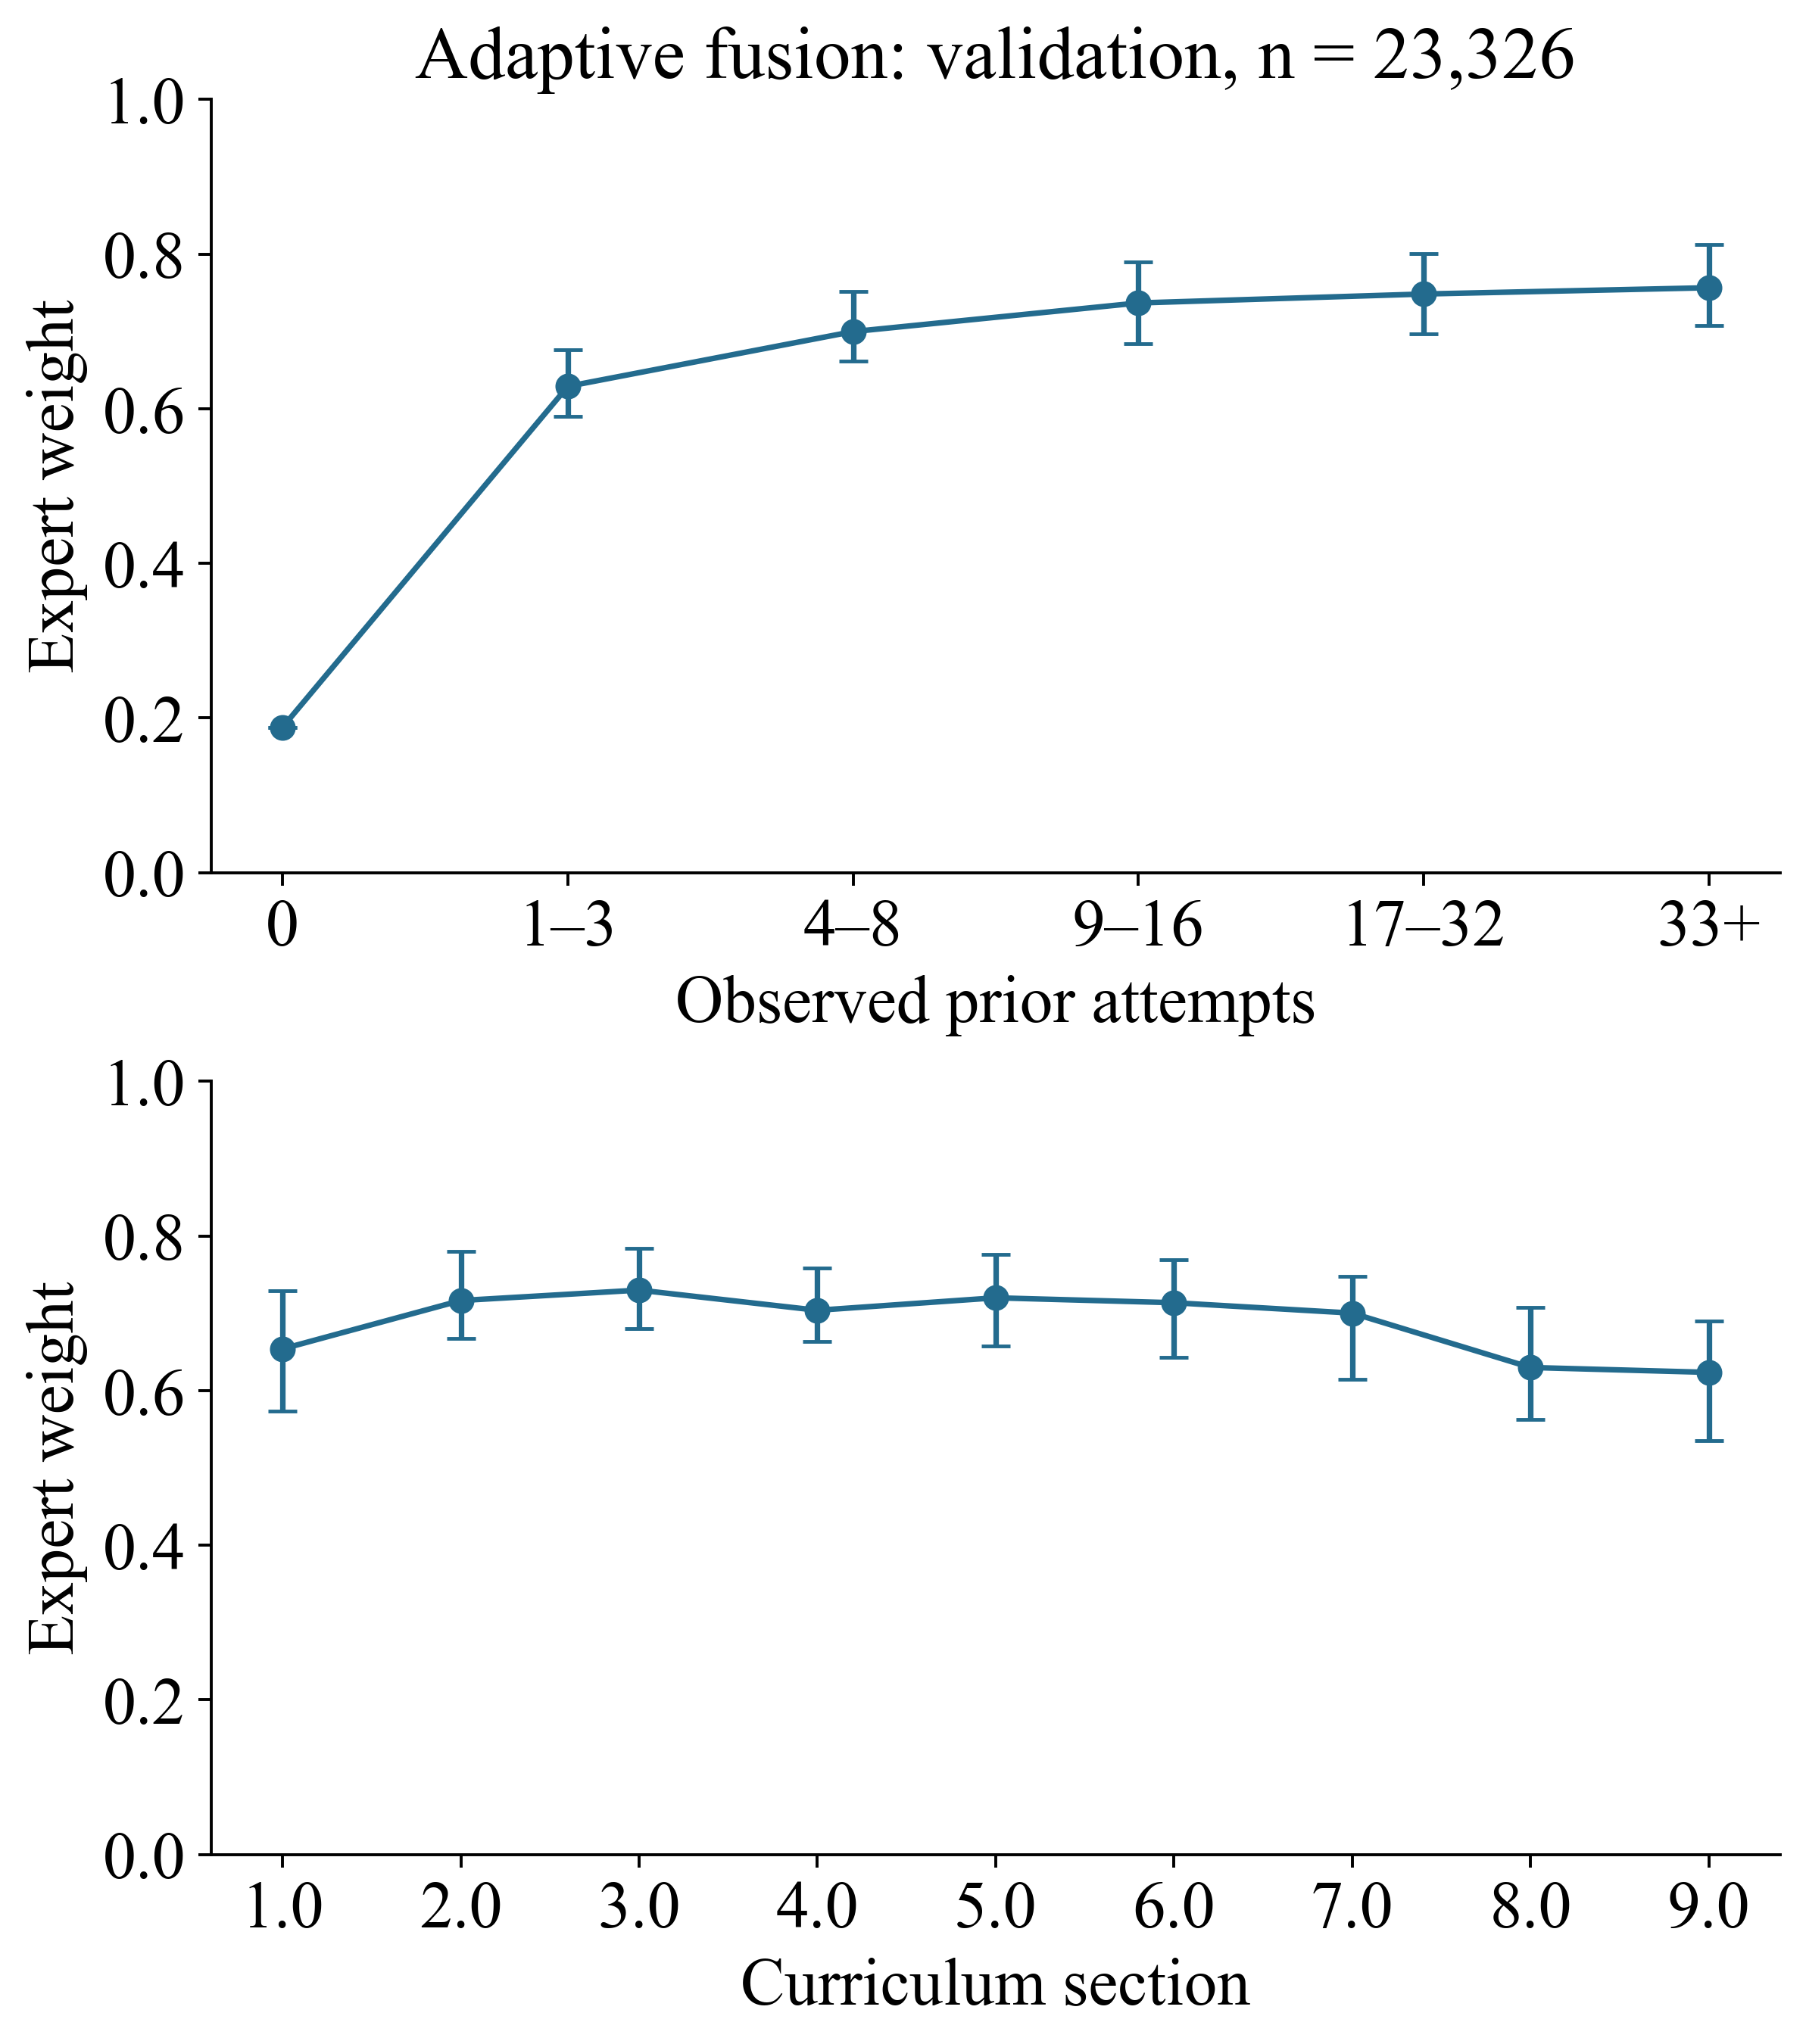

In [23]:
weight_frame = validation_data[["history_n", "q_level"]].copy()
weight_frame["Expert weight"] = chosen_gate["validation_weight"]
weight_frame["History group"] = pd.cut(
    weight_frame.history_n,
    bins=[-1, 0, 3, 8, 16, 32, np.inf],
    labels=["0", "1–3", "4–8", "9–16", "17–32", "33+"],
)
weight_frame.to_csv(ROOT / "Tables/05_gate_behavior.csv", index=False)
fig, axes = plt.subplots(2, 1, figsize=(6.7, 7.6), layout="constrained")
for ax, grouping, label in zip(
    axes,
    ["History group", "q_level"],
    ["Observed prior attempts", "Curriculum section"],
):
    grouped = weight_frame.groupby(grouping, observed=True)["Expert weight"]
    median = grouped.median()
    low = grouped.quantile(0.25)
    high = grouped.quantile(0.75)
    positions = np.arange(len(median))
    ax.errorbar(
        positions,
        median,
        yerr=np.vstack([median - low, high - median]),
        fmt="o-",
        color="#236B8E",
        capsize=4,
    )
    ax.set_xticks(positions, median.index.astype(str))
    ax.set(xlabel=label, ylabel="Expert weight", ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_title(f"Adaptive fusion: validation, n = {len(weight_frame):,}")
save_figure(fig, "05_gate_behavior")
plt.show()

**Interpretation.** The gate trusts the expert more as history accumulates: the median expert weight is 0.19 without history, 0.63 after 1–3 attempts, 0.70–0.74 after 4–16 attempts and 0.76 after more than 32 attempts. Across curriculum sections the median lies between 0.62 and 0.73, with the lowest values in sections 8 and 9. The pattern is a description of the fitted gate, not evidence of a causal effect of experience.

## Computational cost of the expert

The actual time of full training and prediction, the number of active parameters and the size of the saved state are shown. For the full inference path, the selected base, hazard and gate must be added to these costs. Model_MB refers to the checkpoint with the weights and the training vocabulary; the input syntactic cache and the separate preprocessing object are not included. The final comparison in notebook 6 separately accounts for the complete saved bundle of weights, vocabulary and fitted transformations. File size is not a measurement of peak RAM.

In [24]:
efficiency_table = (
    pd.DataFrame(graph_efficiency)
    .groupby(["Model", "Split", "n"], sort=False)
    .agg(
        Train_s=("Train_s", "median"),
        Inference_s=("Inference_s", "median"),
        Parameters=("Parameters", "median"),
        Model_MB=("Model_MB", "median"),
    )
    .reset_index()
)
table(
    efficiency_table,
    "Costs of the structural-temporal variants; medians of measurements",
    "05_efficiency",
)
assert (
    efficiency_table.set_index("Model").loc["FullGraph", "Parameters"]
    == efficiency_table.set_index("Model").loc["NoEdges", "Parameters"]
)

Costs of the structural-temporal variants; medians of measurements

,Model,Split,n,Train_s,Inference_s,Parameters,Model_MB
0,FullGraph,Validation,23326,45.26529,0.18243,39698.0,0.17075
1,NoGraphEncoder,Validation,23326,22.35178,0.08672,28786.0,0.12169
2,NoOrder,Validation,23326,41.15114,0.17669,33362.0,0.14418
3,NoAuxLoss,Validation,23326,44.09808,0.18280,36913.0,0.17075
4,NoEdges,Validation,23326,30.84778,0.16093,39698.0,0.17068
5,NoInteraction,Validation,23326,42.10841,0.17888,31010.0,0.13588
6,NoTaskReadout,Validation,23326,42.79283,0.16702,34194.0,0.14829


**Interpretation.** On the RTX 5070 Laptop GPU a full training run of the expert takes 43–53 s and predicting 23,326 validation queries about 0.2 s; the expert has 39,698 trainable parameters, of which 8,688 belong to the interaction embedding and 5,504 to the task read-out. Training cost is an offline cost; inference is negligible for interactive use.

## Boundary of the subsequent analysis

The architecture, settings and ablations are fixed after this stage. The validation results were used for selection and are therefore not a confirmation of superiority. The next notebook evaluates the locked test once for this configuration and reports that evaluation as non-independent, because the test split had been evaluated before the configuration was selected. It also covers statistical uncertainty, subgroups, calibration, error patterns and robustness scenarios.

In [25]:
save_experiment_state()
frozen = {
    "feature_revision": contract["feature_revision"],
    "base": BASE_NAME,
    "model": "AlphaProg-AGMT",
    "development_protocol": "Protocol/model_development_protocol.json",
    "screen_selection": selected_label,
    "test_independence": "not independent: the test split had been evaluated before this configuration was selected",
    "seeds": SEEDS,
    "graph_config": vars(FULL_CONFIG),
    "epochs": GRAPH_EPOCHS,
    "batch_size": GRAPH_BATCH_SIZE,
    "learning_rate": FULL_CONFIG.learning_rate,
    "gate_regularization": chosen_gate["regularization"],
    "gate_prior": chosen_gate["prior_weight"],
    "gate_novelty": NOVELTY_MODE,
    "gate_grid": {"penalties": list(GATE_PENALTIES), "priors": list(GATE_PRIORS)},
    "selection_split": "Validation",
    "locked_test_opened": True,
    "practical_logloss_difference": 0.005,
    "history_limit": GRAPH_HISTORY,
    "history_task_features": HISTORY_TASK_FEATURES,
    "history_process_features": PROCESS_COLUMNS,
    "probability_aggregation": "arithmetic_mean_across_seeds",
    "effort_seed_aggregation": "mean_p_and_q_then_geometric_cdf",
    "robust_history_mask_fractions": [0.0, 0.1, 0.3],
    "effort_horizons": [1, 3, 5, 10],
    "secondary_effort_comparators": [
        base_decision["best_ml"],
        base_decision["best_dl"],
    ],
    "secondary_effort_intervals": "learner_bootstrap_95pct_pointwise",
    "primary_bootstrap_repetitions": 1000,
    "paired_randomization_repetitions": 2000,
    "familywise_correction": "Holm",
    "ablation_variants": list(VARIANT_CONFIGS),
    "ablation_best_single": "base" if single_name == BASE_NAME else "graph",
    "primary_models": [
        "GlobalMean",
        "ItemMean",
        "LogisticRegression",
        "RandomForest",
        "XGBoost",
        "LightGBM",
        "DKT",
        "AKT",
        "UKT",
        "TabM",
        "GraphTrajectory",
        "AlphaProg-AGMT",
    ],
}
frozen_path = ROOT / "Protocol/frozen_proposed_model.json"
if (ROOT / "Protocol/test_evaluation_boundary.json").exists():
    assert (
        json.loads(frozen_path.read_text()) == frozen
    ), "Reproduction changed the frozen configuration."
else:
    frozen_path.write_text(json.dumps(frozen, indent=2))
source_fingerprints = {}
for training_path in sorted((ROOT / "Notebooks").glob("0[1-5]*.ipynb")):
    training_notebook = json.loads(training_path.read_text())
    training_source = "\n\n".join(
        "".join(cell["source"])
        for cell in training_notebook["cells"]
        if cell["cell_type"] == "code"
    )
    source_fingerprints[training_path.name] = hashlib.sha256(
        training_source.encode()
    ).hexdigest()
fingerprint_path = ROOT / "Protocol/frozen_training_sources.json"
fingerprint_record = {
    "feature_revision": contract["feature_revision"],
    "notebooks": source_fingerprints,
}
if (ROOT / "Protocol/test_evaluation_boundary.json").exists():
    assert json.loads(fingerprint_path.read_text()) == fingerprint_record
else:
    fingerprint_path.write_text(json.dumps(fingerprint_record, indent=2));